# IDRiD Haemorrhages (HE) Segmentation - Comparison of Five Models

## 1. Research objective and selected architectures

**Objective.** Train, validate and test **five** semantic-segmentation architectures for **Haemorrhages** on the IDRiD segmentation sub-challenge (53 training / 27 test annotated images), compare them under identical conditions, select the best one **using validation data only**, and export it with all metadata needed by a separate Python inference API (for a React front-end that combines the four lesion-specific best models into one colour-coded overlay).

**Models compared in this notebook**

| # | Model | Encoder | What is implemented |
|---|---|---|---|
| 1 | **U-Net** | ResNet-34 | Contracting encoder + expanding decoder, bilinear up-sampling, concatenated skip connections at strides 2/4/8/16, final up-sampling stage to full resolution. |
| 2 | **Attention U-Net** | ResNet-34 | The same U-Net, but every skip connection passes through an additive attention gate (Oktay et al., 2018) driven by the up-sampled decoder signal. |
| 3 | **U-Net++** | ResNet-34 | Nested dense skip pathways: node `x[i,j]` concatenates `x[i,0..j-1]` with the up-sampled `x[i+1,j-1]`; output from `x[0,4]`; no deep supervision. |
| 4 | **FPN** | ResNet-34 | Feature Pyramid Network: lateral 1x1 convs, top-down additive pathway, per-level projection, up-sampling to stride 4 and summation, 1x1 classifier, x4 up-sampling. |
| 5 | **DeepLabV3+** | ResNet-50 (dilated, output stride 16) | Atrous Spatial Pyramid Pooling (1x1, 3x3 rates 6/12/18, image pooling) + decoder fusing 48-channel low-level (stride-4) features. |

**Implementation choices, stated openly**
- All encoders are ImageNet-style ResNets. Pretrained weights are *optional*: if the download fails (e.g. offline Colab) the encoder is randomly initialised and this is printed and saved in the metadata. **Check the `encoder_weights` column before comparing** - a model that silently trained from scratch is not comparable.
- DeepLabV3+ uses **ResNet-50** because torchvision can only dilate Bottleneck-block ResNets. Its encoder therefore differs from the other four; encoder size is a confound in the comparison.
- The model list lives in `CFG.model_names` / `MODEL_ZOO`; models can be removed or added in the architecture cell.

**Fair-comparison protocol.** Every model uses the same train/validation split, the same preprocessing and augmentation, the same loss, optimiser, schedule, epochs, early-stopping rule, batch size and seed (same shuffling order). Each model's best checkpoint **and** probability threshold are selected on the validation images only.

**Best-model rule.** The best model is the one with the highest **validation** Dice. Test results are reported for all models, but they are *not* used to choose; choosing by test score would leak the test set into model selection.


**Principles**
- Only valid image-mask pairs (matched by IDRiD numeric ID) are used. *A missing annotation file is not treated as a negative mask.*
- The official IDRiD **test set is untouched** until final evaluation. Checkpoints, thresholds and the best-model choice use **validation data only**.
- Augmentation is applied to training images only.
- Nothing in this notebook has been executed by its author: **no result exists until you run it**. Run with `CFG.smoke_test = True` first (2 epochs per model on a few images) to verify that all five models train end-to-end.
- Predictions are for research. They are **not** a clinical diagnosis.

## 2. Google Drive mounting and dependency installation

Written for Google Colab (GPU runtime recommended: *Runtime -> Change runtime type -> GPU*). PyTorch and torchvision are pre-installed on Colab; missing packages are installed automatically.

In [1]:
import os, sys, importlib.util, subprocess

def _ensure(pip_name, module_name):
    if importlib.util.find_spec(module_name) is None:
        print(f"Installing {pip_name} ...")
        subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", pip_name])

# torch / torchvision are pre-installed on Colab; the others are installed only if missing.
for _pip, _mod in [("torch", "torch"), ("torchvision", "torchvision"), ("numpy", "numpy"),
                   ("pandas", "pandas"), ("matplotlib", "matplotlib"), ("tqdm", "tqdm"),
                   ("Pillow", "PIL"), ("opencv-python-headless", "cv2")]:
    _ensure(_pip, _mod)

try:
    IN_COLAB = importlib.util.find_spec("google.colab") is not None
except ModuleNotFoundError:
    IN_COLAB = False

if IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
else:
    print("Not running in Colab: Google Drive was NOT mounted. Set CFG.root to your local dataset folder.")

Mounted at /content/drive


## 3. Configuration

All hyper-parameters are in one `Config` dataclass - change them **here**. `smoke_test = True` shrinks the data, runs 2 epochs per model and writes to a separate `*_smoke` folder. `resume = True` skips any model whose weights, history and summary are already saved, so a Colab disconnection does not lose finished models.

In [2]:
import os, re, json, time, math, random, copy, platform, warnings
from dataclasses import dataclass, asdict

import numpy as np
import pandas as pd
import cv2
import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision
from torch.utils.data import Dataset, DataLoader
from PIL import Image
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from tqdm.auto import tqdm
from IPython.display import display

cv2.setNumThreads(0)
warnings.filterwarnings("ignore", category=UserWarning)

EXPECTED_COUNTS = {"MA": (54, 27), "HE": (53, 27), "EX": (54, 27), "SE": (26, 14)}  # (train, test)


@dataclass
class Config:
    # ---- experiment identity -------------------------------------------------------------
    lesion_key: str = "HE"
    lesion_name: str = "Haemorrhages"
    gt_folder: str = "2. Haemorrhages"                 # sub-folder inside "2. All Segmentation Groundtruths/<split>"
    mask_suffix: str = "_HE"           # mask files look like IDRiD_01_HE.tif
    model_names: tuple = ("unet", "attention_unet", "unetplusplus", "fpn", "deeplabv3plus")  # models compared here
    resume: bool = True                       # skip training for a model whose results already exist in OUT_DIR
    overlay_color_rgb: tuple = (0, 128, 255)

    # ---- paths ---------------------------------------------------------------------------
    root: str = "/content/drive/MyDrive/Research/A. Segmentation"
    train_img_dir: str = "1. Original Images/a. Training Set"
    test_img_dir: str = "1. Original Images/b. Testing Set"
    train_gt_dir: str = "2. All Segmentation Groundtruths/a. Training Set"
    test_gt_dir: str = "2. All Segmentation Groundtruths/b. Testing Set"

    # ---- data ----------------------------------------------------------------------------
    img_size: int = 256                       # square input; 512 is recommended for MA / EX if GPU memory allows
    val_fraction: float = 0.2
    use_clahe: bool = True
    clahe_clip: float = 2.0
    clahe_tile: int = 8
    mean: tuple = (0.485, 0.456, 0.406)       # ImageNet statistics (encoder is ImageNet-style)
    std: tuple = (0.229, 0.224, 0.225)

    # ---- training ------------------------------------------------------------------------
    seed: int = 42
    batch_size: int = 8                       # must be >= 2 (BatchNorm / ASPP pooling branch)
    epochs: int = 100
    lr: float = 3e-4
    weight_decay: float = 1e-4
    es_patience: int = 25                     # early stopping on validation Dice
    num_workers: int = 2
    use_amp: bool = True
    pretrained_encoder: bool = True           # tries to download ImageNet weights; falls back to random init offline
    bce_weight: float = 1.0
    dice_weight: float = 1.0
    pos_weight_cap: float = 30.0

    # ---- smoke test ----------------------------------------------------------------------
    smoke_test: bool = False                  # <<< set True for a 2-epoch dry run on a handful of images
    smoke_max_train: int = 10
    smoke_max_test: int = 4


CFG = Config()
if CFG.smoke_test:
    CFG.epochs, CFG.batch_size, CFG.num_workers, CFG.es_patience = 2, 2, 0, 2
assert CFG.batch_size >= 2, "batch_size must be >= 2"

def seed_everything(seed):
    random.seed(seed); np.random.seed(seed)
    torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

seed_everything(CFG.seed)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device, "|", torch.cuda.get_device_name(0) if device.type == "cuda" else "CPU only (training will be slow)")
print("torch", torch.__version__, "| torchvision", torchvision.__version__, "| cv2", cv2.__version__)

PREFIX = f"{CFG.lesion_key}_5models"
OUT_DIR = os.path.join(CFG.root, "outputs", PREFIX + ("_smoke" if CFG.smoke_test else ""))
for _sub in ["", "figures"]:
    os.makedirs(os.path.join(OUT_DIR, _sub), exist_ok=True)
print("Outputs will be written to:", OUT_DIR)
print(json.dumps(asdict(CFG), indent=2))

Device: cuda | Tesla T4
torch 2.11.0+cu130 | torchvision 0.26.0+cu130 | cv2 4.14.0
Outputs will be written to: /content/drive/MyDrive/Research/A. Segmentation/outputs/HE_5models
{
  "lesion_key": "HE",
  "lesion_name": "Haemorrhages",
  "gt_folder": "2. Haemorrhages",
  "mask_suffix": "_HE",
  "model_names": [
    "unet",
    "attention_unet",
    "unetplusplus",
    "fpn",
    "deeplabv3plus"
  ],
  "resume": true,
  "overlay_color_rgb": [
    0,
    128,
    255
  ],
  "root": "/content/drive/MyDrive/Research/A. Segmentation",
  "train_img_dir": "1. Original Images/a. Training Set",
  "test_img_dir": "1. Original Images/b. Testing Set",
  "train_gt_dir": "2. All Segmentation Groundtruths/a. Training Set",
  "test_gt_dir": "2. All Segmentation Groundtruths/b. Testing Set",
  "img_size": 256,
  "val_fraction": 0.2,
  "use_clahe": true,
  "clahe_clip": 2.0,
  "clahe_tile": 8,
  "mean": [
    0.485,
    0.456,
    0.406
  ],
  "std": [
    0.229,
    0.224,
    0.225
  ],
  "seed": 42,
 

## 4. Dataset directory verification and image/mask ID matching

Original images (`IDRiD_NN.jpg`) and masks (`IDRiD_NN_HE.tif`) are paired by **numeric ID**, never by sorted position. The code reports images without a mask, masks without an image, duplicate IDs (excluded as ambiguous), unparsable names and image/mask size mismatches (excluded). Images lacking a **HE** annotation are excluded, not treated as negatives.

In [3]:
ID_RE = re.compile(r"IDRiD_(\d+)", re.IGNORECASE)
IMG_EXTS = {".jpg", ".jpeg", ".png", ".tif", ".tiff"}
MASK_EXTS = {".tif", ".tiff", ".png", ".jpg", ".jpeg", ".bmp"}


def index_by_id(folder, exts, required_suffix=None):
    """Return ({numeric id: path}, duplicated ids, unparsable files). Duplicated ids are removed (ambiguous)."""
    if not os.path.isdir(folder):
        raise FileNotFoundError(f"Folder not found: {folder}")
    by_id, dups, bad = {}, set(), []
    for fn in sorted(os.listdir(folder)):
        stem, ext = os.path.splitext(fn)
        if ext.lower() not in exts:
            continue
        m = ID_RE.search(stem)
        if m is None or (required_suffix and not stem.upper().endswith(required_suffix.upper())):
            bad.append(fn)
            continue
        key = int(m.group(1))
        if key in by_id:
            dups.add(key)
        else:
            by_id[key] = os.path.join(folder, fn)
    for d in dups:
        by_id.pop(d, None)
    return by_id, sorted(dups), bad


def build_pairs(split_name, img_dir, gt_dir):
    img_by_id, img_dups, img_bad = index_by_id(img_dir, IMG_EXTS)
    msk_by_id, msk_dups, msk_bad = index_by_id(gt_dir, MASK_EXTS, required_suffix=CFG.mask_suffix)
    rows, size_mismatch = [], []
    for i in sorted(set(img_by_id) & set(msk_by_id)):
        with Image.open(img_by_id[i]) as a:
            iw, ih = a.size
        with Image.open(msk_by_id[i]) as b:
            mw, mh = b.size
        if (iw, ih) != (mw, mh):
            size_mismatch.append((i, (iw, ih), (mw, mh)))
            continue
        rows.append(dict(split=split_name, image_id=i, image_path=img_by_id[i], mask_path=msk_by_id[i], width=iw, height=ih))
    df = pd.DataFrame(rows, columns=["split", "image_id", "image_path", "mask_path", "width", "height"])
    report = dict(
        n_images=len(img_by_id), n_masks=len(msk_by_id), n_valid_pairs=len(df),
        images_without_this_lesion_mask=sorted(set(img_by_id) - set(msk_by_id)),
        masks_without_image=sorted(set(msk_by_id) - set(img_by_id)),
        duplicate_image_ids=img_dups, duplicate_mask_ids=msk_dups,
        unparsable_image_files=img_bad, unparsable_mask_files=msk_bad, size_mismatch=size_mismatch)
    return df, report


def print_report(name, rep, expected):
    print(f"=== {name} ===")
    print(f"  original images found        : {rep['n_images']}")
    print(f"  {CFG.lesion_key} masks found (unique ids)      : {rep['n_masks']}   (expected {expected})")
    print(f"  VALID image-mask pairs       : {rep['n_valid_pairs']}")
    print(f"  images with NO {CFG.lesion_key} annotation   : {len(rep['images_without_this_lesion_mask'])} "
          "-> EXCLUDED (a missing annotation is NOT a negative mask)")
    for k in ["masks_without_image", "duplicate_image_ids", "duplicate_mask_ids", "unparsable_image_files",
              "unparsable_mask_files", "size_mismatch"]:
        if rep[k]:
            print(f"  [WARN] {k}: {rep[k][:15]}{' ...' if len(rep[k]) > 15 else ''}")
    if rep["n_masks"] != expected:
        print(f"  [WARN] mask count differs from the documented IDRiD count ({expected}). Check the folder contents.")


R = lambda *p: os.path.join(CFG.root, *p)
train_pairs, train_rep = build_pairs("train", R(CFG.train_img_dir), R(CFG.train_gt_dir, CFG.gt_folder))
test_pairs, test_rep = build_pairs("test", R(CFG.test_img_dir), R(CFG.test_gt_dir, CFG.gt_folder))
print_report("Official TRAINING set", train_rep, EXPECTED_COUNTS[CFG.lesion_key][0])
print_report("Official TESTING set", test_rep, EXPECTED_COUNTS[CFG.lesion_key][1])

assert len(train_pairs) > 0, "No valid training pairs found - check paths / file naming."
assert len(test_pairs) > 0, "No valid testing pairs found - check paths / file naming."
assert set(train_pairs.image_id).isdisjoint(set(test_pairs.image_id)), "Train/test ids overlap!"

if CFG.smoke_test:
    train_pairs = train_pairs.iloc[:CFG.smoke_max_train].reset_index(drop=True)
    test_pairs = test_pairs.iloc[:CFG.smoke_max_test].reset_index(drop=True)
    print(f"[SMOKE TEST] using {len(train_pairs)} training and {len(test_pairs)} test pairs only")

display(train_pairs.head())

=== Official TRAINING set ===
  original images found        : 54
  HE masks found (unique ids)      : 53   (expected 53)
  VALID image-mask pairs       : 53
  images with NO HE annotation   : 1 -> EXCLUDED (a missing annotation is NOT a negative mask)
=== Official TESTING set ===
  original images found        : 27
  HE masks found (unique ids)      : 27   (expected 27)
  VALID image-mask pairs       : 27
  images with NO HE annotation   : 0 -> EXCLUDED (a missing annotation is NOT a negative mask)


,split,image_id,image_path,mask_path,width,height
0,train,1,/content/drive/MyDrive/Research/A. Segmentatio...,/content/drive/MyDrive/Research/A. Segmentatio...,4288,2848
1,train,2,/content/drive/MyDrive/Research/A. Segmentatio...,/content/drive/MyDrive/Research/A. Segmentatio...,4288,2848
2,train,3,/content/drive/MyDrive/Research/A. Segmentatio...,/content/drive/MyDrive/Research/A. Segmentatio...,4288,2848
3,train,4,/content/drive/MyDrive/Research/A. Segmentatio...,/content/drive/MyDrive/Research/A. Segmentatio...,4288,2848
4,train,5,/content/drive/MyDrive/Research/A. Segmentatio...,/content/drive/MyDrive/Research/A. Segmentatio...,4288,2848


## 5. Class imbalance and positive-pixel statistics

Only the official **training** pairs are read here. Statistics are measured at original resolution *and* after resizing, because nearest-neighbour down-sampling can remove tiny lesion pixels.

Loading training pairs:   0%|          | 0/53 [00:00<?, ?it/s]

Valid training images                         : 53
Positive-pixel fraction (original resolution) : 0.010043 -> background:lesion ~ 100:1
Positive-pixel fraction (resized 256px)       : 0.010029
Images whose mask is empty at original size   : 0
Images whose mask becomes EMPTY after nearest-neighbour resizing: 0
Lesion pixel retention after nearest resize (resized / area-scaled original): 1.00 (1.0 = ideal)


,mean,min,50%,max
image_id,27.207547,1.000000,27.000000,5.400000e+01
orig_h,2848.000000,2848.000000,2848.000000,2.848000e+03
orig_w,4288.000000,4288.000000,4288.000000,4.288000e+03
orig_pos_pixels,122650.660377,2149.000000,58339.000000,1.821322e+06
orig_pos_fraction,0.010043,0.000176,0.004777,1.491393e-01
resized_pos_pixels,657.264151,14.000000,311.000000,9.747000e+03
resized_pos_fraction,0.010029,0.000214,0.004745,1.487274e-01
components,25.754717,2.000000,22.000000,1.060000e+02


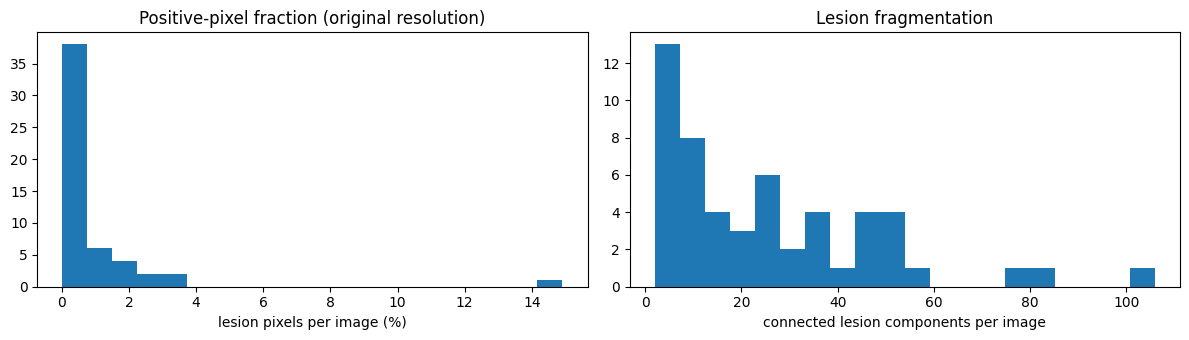

In [4]:
def read_rgb(path):
    img = cv2.imread(path, cv2.IMREAD_COLOR)
    if img is None:
        img = np.array(Image.open(path).convert("RGB"))
        return img
    return cv2.cvtColor(img, cv2.COLOR_BGR2RGB)


def read_mask_binary(path):
    m = cv2.imread(path, cv2.IMREAD_UNCHANGED)
    if m is None:
        m = np.array(Image.open(path))
    if m.ndim == 3:
        m = m.max(axis=2)
    return (m > 0).astype(np.uint8)          # any non-zero pixel is lesion


def load_raw_pair(row, size):
    """Load one valid image-mask pair; resize image (INTER_AREA) and mask (INTER_NEAREST)."""
    img = read_rgb(row.image_path)
    msk = read_mask_binary(row.mask_path)
    if img.shape[:2] != msk.shape[:2]:
        raise ValueError(f"image {img.shape[:2]} and mask {msk.shape[:2]} sizes differ")
    h, w = img.shape[:2]
    return dict(
        id=int(row.image_id),
        image=cv2.resize(img, (size, size), interpolation=cv2.INTER_AREA),
        mask=cv2.resize(msk, (size, size), interpolation=cv2.INTER_NEAREST),
        orig_hw=(h, w),
        orig_pos=int(msk.sum()),
        orig_components=int(cv2.connectedComponents(msk, connectivity=8)[0] - 1),
    )


def build_raw_cache(pairs_df, desc):
    cache, errors = {}, []
    for row in tqdm(list(pairs_df.itertuples(index=False)), desc=desc):
        try:
            cache[int(row.image_id)] = load_raw_pair(row, CFG.img_size)
        except Exception as e:                           # never silently drop a pair
            errors.append((int(row.image_id), repr(e)))
    if errors:
        print("[WARN] pairs excluded because they could not be loaded:", errors)
    return cache, errors


# Only the official TRAINING pairs are loaded here. The official test set is loaded later, only for final evaluation.
raw_train, train_errors = build_raw_cache(train_pairs, "Loading training pairs")

stats = pd.DataFrame([dict(
    image_id=i, orig_h=d["orig_hw"][0], orig_w=d["orig_hw"][1],
    orig_pos_pixels=d["orig_pos"], orig_pos_fraction=d["orig_pos"] / (d["orig_hw"][0] * d["orig_hw"][1]),
    resized_pos_pixels=int(d["mask"].sum()), resized_pos_fraction=float(d["mask"].mean()),
    components=d["orig_components"]) for i, d in sorted(raw_train.items())])

total_orig = (stats.orig_h * stats.orig_w).sum()
print(f"Valid training images                         : {len(stats)}")
print(f"Positive-pixel fraction (original resolution) : {stats.orig_pos_pixels.sum() / total_orig:.6f} "
      f"-> background:lesion ~ {total_orig / max(stats.orig_pos_pixels.sum(), 1):.0f}:1")
print(f"Positive-pixel fraction (resized {CFG.img_size}px)       : {stats.resized_pos_pixels.sum() / (len(stats) * CFG.img_size ** 2):.6f}")
print(f"Images whose mask is empty at original size   : {(stats.orig_pos_pixels == 0).sum()}")
lost = stats[(stats.orig_pos_pixels > 0) & (stats.resized_pos_pixels == 0)]
print(f"Images whose mask becomes EMPTY after nearest-neighbour resizing: {len(lost)}"
      + (f"  ids={lost.image_id.tolist()}  -> consider a larger CFG.img_size" if len(lost) else ""))
retained = stats.resized_pos_pixels.sum() / (stats.orig_pos_pixels.sum() * (CFG.img_size ** 2) / (stats.orig_h * stats.orig_w).mean())
print(f"Lesion pixel retention after nearest resize (resized / area-scaled original): {retained:.2f} (1.0 = ideal)")
display(stats.describe().T[["mean", "min", "50%", "max"]])

fig, ax = plt.subplots(1, 2, figsize=(12, 3.5))
ax[0].hist(stats.orig_pos_fraction[stats.orig_pos_fraction > 0] * 100, bins=20)
ax[0].set_xlabel("lesion pixels per image (%)"); ax[0].set_title("Positive-pixel fraction (original resolution)")
ax[1].hist(stats.components, bins=20)
ax[1].set_xlabel("connected lesion components per image"); ax[1].set_title("Lesion fragmentation")
plt.tight_layout(); plt.show()

## 6. Image preprocessing and mask preprocessing

- **Images:** RGB -> resize to `CFG.img_size` (`INTER_AREA`) -> **CLAHE** on the L channel of LAB -> /255 -> ImageNet mean/std normalisation (all five encoders are ImageNet-style ResNets).
- **Why CLAHE:** fundus photographs have uneven illumination and low local contrast for small lesions; CLAHE on luminance raises local contrast without distorting colour. One function applies it identically to training, validation, test and the exported API code; switch off with `CFG.use_clahe = False`. Its benefit is not ablated here.
- **Masks:** any non-zero pixel -> lesion (1); resized with **nearest-neighbour** so values stay in {0, 1}.

In [5]:
def enhance_rgb(img_rgb, clip=None, tile=None):
    """CLAHE on the L channel of LAB: boosts local contrast of small lesions while keeping colour balance."""
    clip = CFG.clahe_clip if clip is None else clip
    tile = CFG.clahe_tile if tile is None else tile
    lab = cv2.cvtColor(img_rgb, cv2.COLOR_RGB2LAB)
    lab[..., 0] = cv2.createCLAHE(clipLimit=clip, tileGridSize=(tile, tile)).apply(lab[..., 0])
    return cv2.cvtColor(lab, cv2.COLOR_LAB2RGB)


def preprocess_resized_rgb(img_rgb_resized):
    """Pipeline order (identical for train / val / test / API): RGB -> resize(INTER_AREA) -> CLAHE -> /255 -> normalise."""
    return enhance_rgb(img_rgb_resized) if CFG.use_clahe else img_rgb_resized


MEAN = np.array(CFG.mean, dtype=np.float32)
STD = np.array(CFG.std, dtype=np.float32)


def to_tensor(img_uint8):
    x = (img_uint8.astype(np.float32) / 255.0 - MEAN) / STD
    return torch.from_numpy(np.ascontiguousarray(x.transpose(2, 0, 1)))


def overlay_mask(img_rgb, mask, color, alpha=0.55):
    out = img_rgb.astype(np.float32).copy()
    m = mask.astype(bool)
    out[m] = (1 - alpha) * out[m] + alpha * np.array(color, dtype=np.float32)
    return out.clip(0, 255).astype(np.uint8)


# Masks: already binary {0,1} uint8 and resized with nearest-neighbour (no new grey values are created).
for d in raw_train.values():
    d["enhanced"] = preprocess_resized_rgb(d["image"])
    assert set(np.unique(d["mask"])).issubset({0, 1})
print("Preprocessing finished for", len(raw_train), "training images. CLAHE:", CFG.use_clahe)

Preprocessing finished for 53 training images. CLAHE: True


## 7. Visualization of original images and ground-truth masks

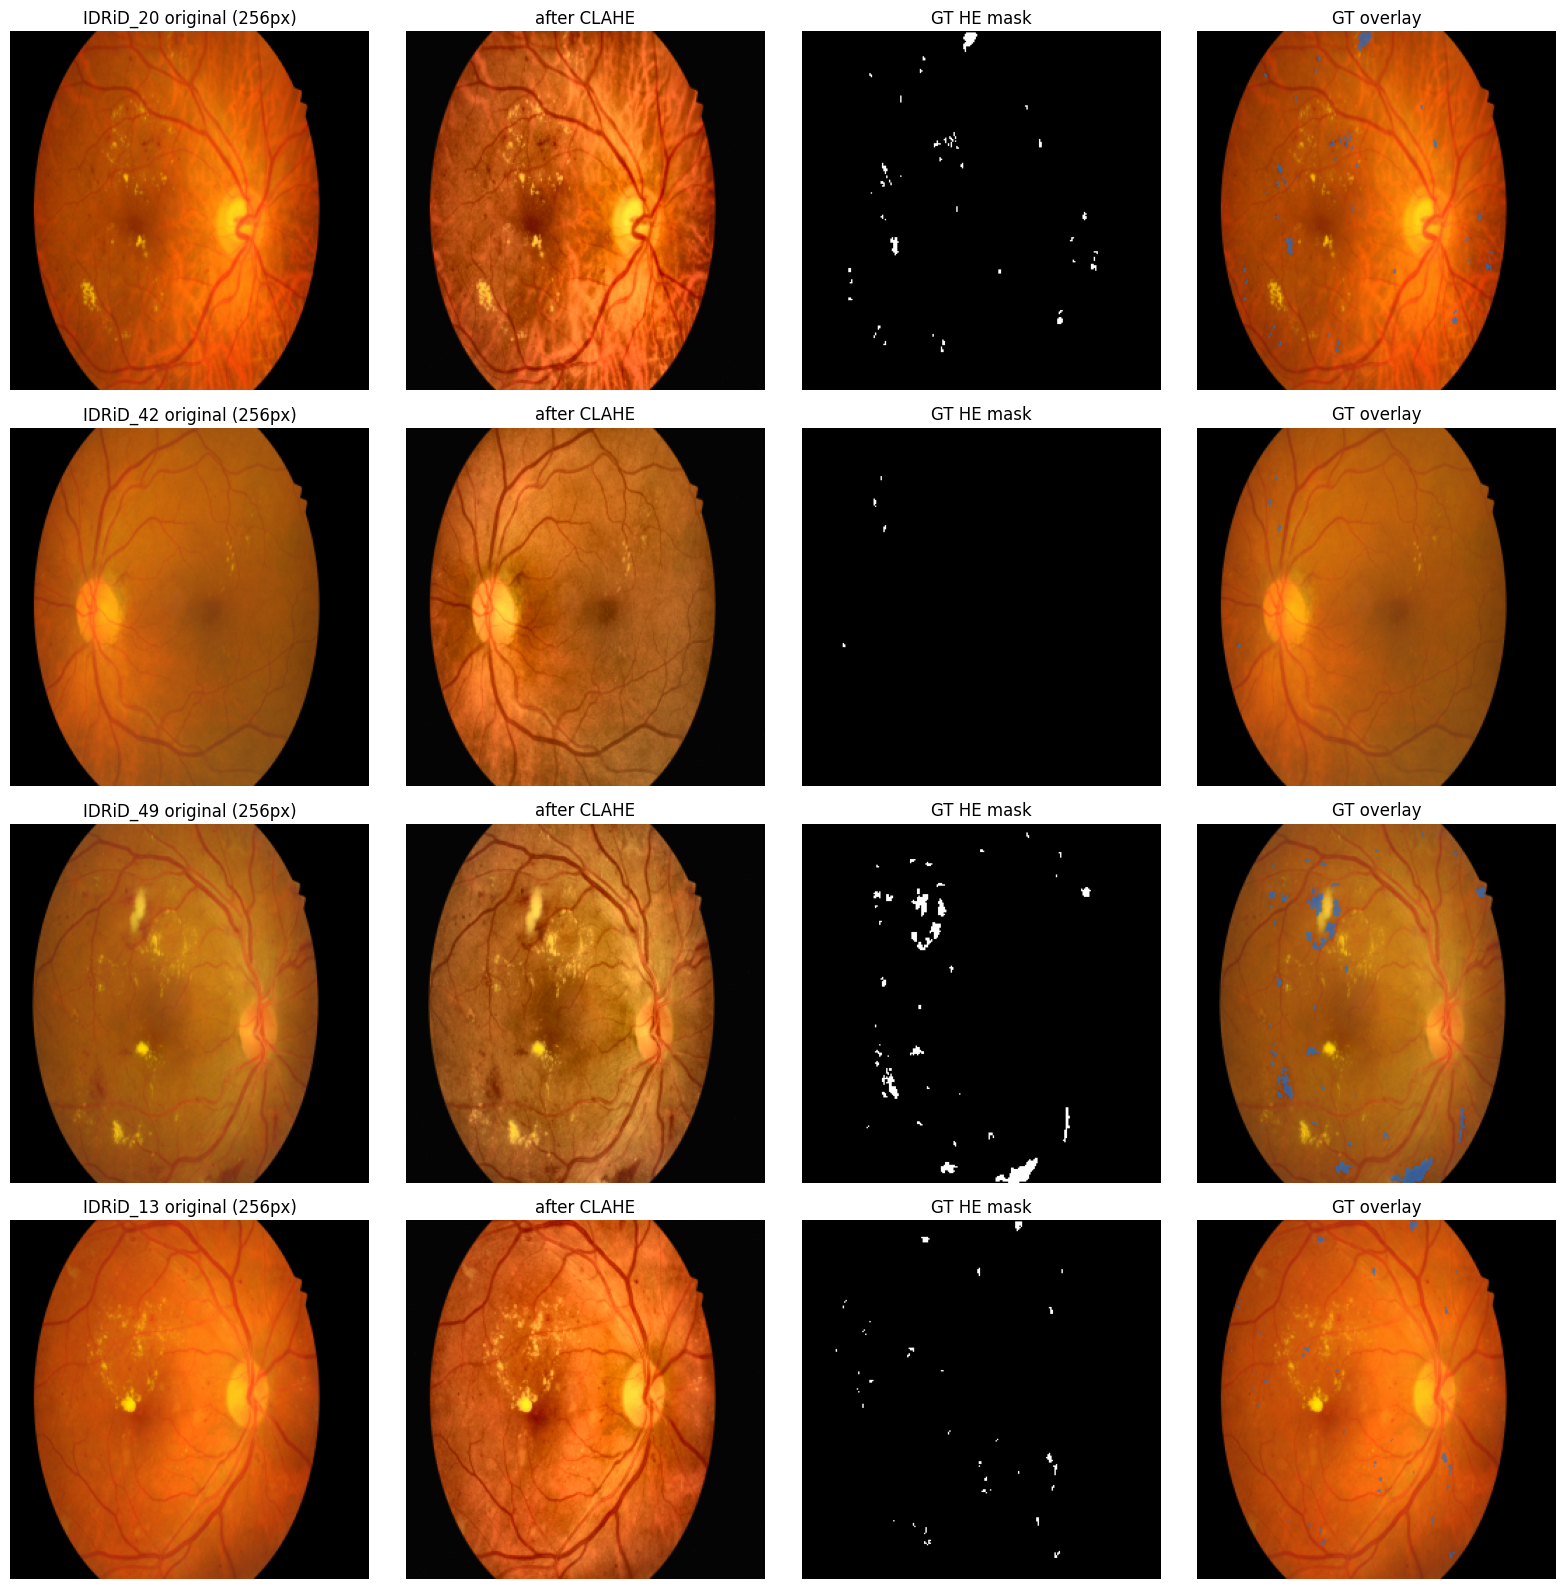

In [6]:
cand = [i for i, d in sorted(raw_train.items()) if d["mask"].sum() > 0]
sel = list(np.random.RandomState(CFG.seed).choice(cand, size=min(4, len(cand)), replace=False))
fig, axes = plt.subplots(len(sel), 4, figsize=(16, 4 * len(sel)), squeeze=False)
for r, i in enumerate(sel):
    d = raw_train[i]
    axes[r, 0].imshow(d["image"]);    axes[r, 0].set_title(f"IDRiD_{i:02d} original ({CFG.img_size}px)")
    axes[r, 1].imshow(d["enhanced"]); axes[r, 1].set_title("after CLAHE" if CFG.use_clahe else "no enhancement")
    axes[r, 2].imshow(d["mask"], cmap="gray", vmin=0, vmax=1); axes[r, 2].set_title(f"GT {CFG.lesion_key} mask")
    axes[r, 3].imshow(overlay_mask(d["image"], d["mask"], CFG.overlay_color_rgb)); axes[r, 3].set_title("GT overlay")
    for a in axes[r]:
        a.axis("off")
plt.tight_layout(); plt.show()

## 8. Train-validation split (official test set untouched)

The valid official-training pairs are split at **image level** with a fixed seed, and the same split is used for all five models. The official test pairs never enter this split (asserted). IDRiD gives no patient identifiers, so a patient-level split is impossible - see limitations.

In [7]:
all_train_ids = sorted(raw_train.keys())
rng = np.random.RandomState(CFG.seed)
perm = rng.permutation(all_train_ids)
n_val = max(1, int(round(len(perm) * CFG.val_fraction)))
val_ids = sorted(int(i) for i in perm[:n_val])
train_ids = sorted(int(i) for i in perm[n_val:])

assert set(train_ids).isdisjoint(val_ids), "train/val leakage"
assert set(train_ids + val_ids).isdisjoint(set(test_pairs.image_id)), "train/val leakage into the official test set"
print(f"train: {len(train_ids)} images | validation: {len(val_ids)} images | official test (untouched): {len(test_pairs)} images")
print("validation ids:", val_ids)

with open(os.path.join(OUT_DIR, f"{PREFIX}_split_ids.json"), "w") as f:
    json.dump(dict(seed=CFG.seed, train_ids=train_ids, val_ids=val_ids, test_ids=[int(i) for i in test_pairs.image_id]), f, indent=2)

if sum(raw_train[i]["mask"].sum() for i in val_ids) == 0:
    print("[WARN] validation masks contain no lesion pixels - validation Dice will be meaningless. Change CFG.seed or val_fraction.")

train: 42 images | validation: 11 images | official test (untouched): 27 images
validation ids: [4, 6, 13, 14, 18, 20, 33, 42, 45, 49, 52]


## 9. PyTorch Dataset and DataLoader

Training augmentation: horizontal/vertical flips, random 90-degree rotations, small affine rotation (+-20 degrees) and scale (0.9-1.1) applied *identically* to image and mask (bilinear / nearest), plus mild brightness/contrast jitter on the image only. Validation and test data are never augmented. `make_loaders()` rebuilds the loaders with the same seed for each model.

In [8]:
def augment(img, msk):
    """Geometric augmentation is applied identically to image and mask (bilinear / nearest). Colour jitter: image only."""
    if random.random() < 0.5:
        img, msk = img[:, ::-1], msk[:, ::-1]
    if random.random() < 0.5:
        img, msk = img[::-1], msk[::-1]
    k = random.randint(0, 3)
    if k:
        img, msk = np.rot90(img, k), np.rot90(msk, k)
    img, msk = np.ascontiguousarray(img), np.ascontiguousarray(msk)
    if random.random() < 0.5:
        h, w = img.shape[:2]
        M = cv2.getRotationMatrix2D((w / 2, h / 2), random.uniform(-20, 20), random.uniform(0.9, 1.1))
        img = cv2.warpAffine(img, M, (w, h), flags=cv2.INTER_LINEAR, borderMode=cv2.BORDER_CONSTANT, borderValue=0)
        msk = cv2.warpAffine(msk, M, (w, h), flags=cv2.INTER_NEAREST, borderMode=cv2.BORDER_CONSTANT, borderValue=0)
    if random.random() < 0.5:
        img = cv2.convertScaleAbs(img, alpha=random.uniform(0.9, 1.1), beta=random.uniform(-10, 10))
    return img, msk


class LesionDataset(Dataset):
    def __init__(self, ids, cache, train):
        self.ids, self.cache, self.train = list(ids), cache, train

    def __len__(self):
        return len(self.ids)

    def __getitem__(self, idx):
        d = self.cache[self.ids[idx]]
        img, msk = d["enhanced"], d["mask"]
        if self.train:                                   # augmentation: TRAINING ONLY
            img, msk = augment(img, msk)
        return to_tensor(img), torch.from_numpy(np.ascontiguousarray(msk[None].astype(np.float32)))


def worker_init_fn(worker_id):
    s = torch.initial_seed() % (2 ** 32)
    random.seed(s); np.random.seed(s)



train_ds = LesionDataset(train_ids, raw_train, train=True)
val_ds = LesionDataset(val_ids, raw_train, train=False)


def make_loaders():
    """Fresh loaders with the same seeded shuffling for every model (fair comparison)."""
    g = torch.Generator().manual_seed(CFG.seed)
    tl = DataLoader(train_ds, batch_size=CFG.batch_size, shuffle=True, drop_last=len(train_ds) >= CFG.batch_size,
                    num_workers=CFG.num_workers, worker_init_fn=worker_init_fn, generator=g,
                    pin_memory=device.type == "cuda")
    vl = DataLoader(val_ds, batch_size=CFG.batch_size, shuffle=False, num_workers=0)
    return tl, vl


_tl, _vl = make_loaders()
xb, yb = next(iter(_tl))
print("train batch:", tuple(xb.shape), xb.dtype, "| mask batch:", tuple(yb.shape), "unique:", torch.unique(yb).tolist())

train batch: (8, 3, 256, 256) torch.float32 | mask batch: (8, 1, 256, 256) unique: [0.0, 1.0]


## 10. Complete architecture definitions (five models)

Shared ResNet encoder and building blocks, followed by U-Net, Attention U-Net, U-Net++, FPN and DeepLabV3+, and the `MODEL_ZOO` registry used by the training loop. A separate inference API needs only the class of the selected best model (or the optional TorchScript file).

In [9]:
RESNET_CHANNELS = {"resnet34": [64, 64, 128, 256, 512], "resnet50": [64, 256, 512, 1024, 2048]}
RESNET_WEIGHTS = {"resnet34": "ResNet34_Weights", "resnet50": "ResNet50_Weights"}


class ResNetEncoder(nn.Module):
    """ResNet feature extractor returning 5 maps at strides 2, 4, 8, 16, 32 (or 16 / 8 when dilated for DeepLabV3+).
    ImageNet weights are optional; if the download fails (offline Colab, no internet) random initialisation is used."""

    def __init__(self, name="resnet34", pretrained=True, output_stride=32):
        super().__init__()
        dilation = {32: [False, False, False], 16: [False, False, True], 8: [False, True, True]}[output_stride]
        if any(dilation) and name == "resnet34":
            raise ValueError("Dilated ResNet needs Bottleneck blocks (use resnet50).")
        net = getattr(torchvision.models, name)(weights=None, replace_stride_with_dilation=dilation)
        self.weights_loaded = False
        if pretrained:
            try:
                w = getattr(getattr(torchvision.models, RESNET_WEIGHTS[name]), "IMAGENET1K_V1")
                net.load_state_dict(w.get_state_dict(progress=True))
                self.weights_loaded = True
                print(f"[OK] loaded ImageNet weights for {name}")
            except Exception as e:
                print(f"[WARN] could not load pretrained weights ({type(e).__name__}: {e}). Using RANDOM initialisation.")
        self.conv1, self.bn1, self.relu, self.maxpool = net.conv1, net.bn1, net.relu, net.maxpool
        self.layer1, self.layer2, self.layer3, self.layer4 = net.layer1, net.layer2, net.layer3, net.layer4
        self.channels = RESNET_CHANNELS[name]

    def forward(self, x):
        f0 = self.relu(self.bn1(self.conv1(x)))      # stride 2
        f1 = self.layer1(self.maxpool(f0))           # stride 4
        f2 = self.layer2(f1)                         # stride 8
        f3 = self.layer3(f2)                         # stride 16
        f4 = self.layer4(f3)                         # stride 32 (16 / 8 if dilated)
        return [f0, f1, f2, f3, f4]


class ConvBNReLU(nn.Sequential):
    def __init__(self, in_ch, out_ch, k=3, dilation=1):
        super().__init__(nn.Conv2d(in_ch, out_ch, k, padding=dilation * (k // 2), dilation=dilation, bias=False),
                         nn.BatchNorm2d(out_ch), nn.ReLU(inplace=True))


class DoubleConv(nn.Sequential):
    def __init__(self, in_ch, out_ch):
        super().__init__(ConvBNReLU(in_ch, out_ch), ConvBNReLU(out_ch, out_ch))



class UpBlock(nn.Module):
    """Upsample x2 (bilinear) -> concatenate encoder skip connection -> two 3x3 conv-BN-ReLU."""

    def __init__(self, in_ch, skip_ch, out_ch):
        super().__init__()
        self.conv = DoubleConv(in_ch + skip_ch, out_ch)

    def forward(self, x, skip=None):
        if skip is not None:
            x = F.interpolate(x, size=skip.shape[-2:], mode="bilinear", align_corners=False)
            x = torch.cat([x, skip], dim=1)
        else:
            x = F.interpolate(x, scale_factor=2, mode="bilinear", align_corners=False)
        return self.conv(x)


class UNet(nn.Module):
    """U-Net: contracting path (ResNet encoder) + expanding path with skip connections at strides 2, 4, 8, 16,
    plus a last up-sampling stage (no skip) that restores the input resolution. Output = logits (1 channel)."""

    def __init__(self, encoder_name="resnet34", pretrained=True, decoder_channels=(256, 128, 64, 32, 16), num_classes=1):
        super().__init__()
        self.encoder = ResNetEncoder(encoder_name, pretrained, 32)
        c, d = self.encoder.channels, decoder_channels
        self.up4 = UpBlock(c[4], c[3], d[0])
        self.up3 = UpBlock(d[0], c[2], d[1])
        self.up2 = UpBlock(d[1], c[1], d[2])
        self.up1 = UpBlock(d[2], c[0], d[3])
        self.up0 = UpBlock(d[3], 0, d[4])
        self.head = nn.Conv2d(d[4], num_classes, kernel_size=1)

    def forward(self, x):
        f0, f1, f2, f3, f4 = self.encoder(x)
        y = self.up4(f4, f3)
        y = self.up3(y, f2)
        y = self.up2(y, f1)
        y = self.up1(y, f0)
        y = self.up0(y, None)
        out = self.head(y)
        if out.shape[-2:] != x.shape[-2:]:
            out = F.interpolate(out, size=x.shape[-2:], mode="bilinear", align_corners=False)
        return out





class AttentionGate(nn.Module):
    """Additive attention gate (Oktay et al., 2018): the decoder signal g re-weights the encoder skip features x."""

    def __init__(self, g_ch, x_ch, inter_ch):
        super().__init__()
        self.wg = nn.Sequential(nn.Conv2d(g_ch, inter_ch, 1, bias=False), nn.BatchNorm2d(inter_ch))
        self.wx = nn.Sequential(nn.Conv2d(x_ch, inter_ch, 1, bias=False), nn.BatchNorm2d(inter_ch))
        self.psi = nn.Sequential(nn.Conv2d(inter_ch, 1, 1), nn.BatchNorm2d(1), nn.Sigmoid())
        self.relu = nn.ReLU(inplace=True)

    def forward(self, g, x):
        return x * self.psi(self.relu(self.wg(g) + self.wx(x)))


class AttUpBlock(nn.Module):
    """Upsample -> attention-gate the skip connection with the upsampled decoder signal -> concatenate -> two convs."""

    def __init__(self, in_ch, skip_ch, out_ch):
        super().__init__()
        self.gate = AttentionGate(in_ch, skip_ch, max(skip_ch // 2, 8))
        self.conv = DoubleConv(in_ch + skip_ch, out_ch)

    def forward(self, x, skip):
        x = F.interpolate(x, size=skip.shape[-2:], mode="bilinear", align_corners=False)
        skip = self.gate(x, skip)
        return self.conv(torch.cat([x, skip], dim=1))


class AttentionUNet(nn.Module):
    """Attention U-Net: the U-Net above with an attention gate on each of the four skip connections."""

    def __init__(self, encoder_name="resnet34", pretrained=True, decoder_channels=(256, 128, 64, 32, 16), num_classes=1):
        super().__init__()
        self.encoder = ResNetEncoder(encoder_name, pretrained, 32)
        c, d = self.encoder.channels, decoder_channels
        self.up4 = AttUpBlock(c[4], c[3], d[0])
        self.up3 = AttUpBlock(d[0], c[2], d[1])
        self.up2 = AttUpBlock(d[1], c[1], d[2])
        self.up1 = AttUpBlock(d[2], c[0], d[3])
        self.up0 = UpBlock(d[3], 0, d[4])
        self.head = nn.Conv2d(d[4], num_classes, kernel_size=1)

    def forward(self, x):
        f0, f1, f2, f3, f4 = self.encoder(x)
        y = self.up4(f4, f3)
        y = self.up3(y, f2)
        y = self.up2(y, f1)
        y = self.up1(y, f0)
        y = self.up0(y, None)
        out = self.head(y)
        if out.shape[-2:] != x.shape[-2:]:
            out = F.interpolate(out, size=x.shape[-2:], mode="bilinear", align_corners=False)
        return out



class UNetPlusPlus(nn.Module):
    """U-Net++ (Zhou et al., 2018): nested, dense skip pathways.
    Node x[i,j] (i = encoder depth, j = column of the nested decoder) receives
        x[i,0], x[i,1], ..., x[i,j-1]  (same-level dense skips)  +  up(x[i+1,j-1])  (deeper level)
    The final output is read from x[0,4] (no deep supervision in this notebook) followed by a last x2 up-sampling stage."""

    def __init__(self, encoder_name="resnet34", pretrained=True, node_channels=(32, 64, 128, 256), num_classes=1):
        super().__init__()
        self.encoder = ResNetEncoder(encoder_name, pretrained, 32)
        enc = self.encoder.channels                       # 5 encoder levels: strides 2 .. 32
        n_levels = len(enc)                               # 5
        ch = {(i, 0): enc[i] for i in range(n_levels)}
        for j in range(1, n_levels):
            for i in range(n_levels - j):
                ch[(i, j)] = node_channels[i]
        self.n_levels = n_levels
        self.blocks = nn.ModuleDict()
        for j in range(1, n_levels):
            for i in range(n_levels - j):
                in_ch = sum(ch[(i, k)] for k in range(j)) + ch[(i + 1, j - 1)]
                self.blocks[f"x_{i}_{j}"] = DoubleConv(in_ch, ch[(i, j)])
        self.final_block = DoubleConv(ch[(0, n_levels - 1)], 16)
        self.head = nn.Conv2d(16, num_classes, kernel_size=1)

    def forward(self, x):
        feats = self.encoder(x)
        nodes = {(i, 0): feats[i] for i in range(self.n_levels)}
        for j in range(1, self.n_levels):
            for i in range(self.n_levels - j):
                up = F.interpolate(nodes[(i + 1, j - 1)], size=nodes[(i, 0)].shape[-2:], mode="bilinear", align_corners=False)
                cat = torch.cat([nodes[(i, k)] for k in range(j)] + [up], dim=1)
                nodes[(i, j)] = self.blocks[f"x_{i}_{j}"](cat)
        y = nodes[(0, self.n_levels - 1)]
        y = F.interpolate(y, scale_factor=2, mode="bilinear", align_corners=False)
        out = self.head(self.final_block(y))
        if out.shape[-2:] != x.shape[-2:]:
            out = F.interpolate(out, size=x.shape[-2:], mode="bilinear", align_corners=False)
        return out





class FPN(nn.Module):
    """Feature Pyramid Network for segmentation (Lin et al., 2017): lateral 1x1 convs on encoder strides 4/8/16/32,
    top-down pathway with additive merging, 3x3 smoothing, then every pyramid level is projected, up-sampled to
    stride 4 and summed; a 1x1 classifier follows and the logits are up-sampled x4 to the input size."""

    def __init__(self, encoder_name="resnet34", pretrained=True, pyramid_channels=128, seg_channels=64, num_classes=1):
        super().__init__()
        self.encoder = ResNetEncoder(encoder_name, pretrained, 32)
        c = self.encoder.channels
        self.lateral = nn.ModuleList([nn.Conv2d(c[k], pyramid_channels, 1) for k in (4, 3, 2, 1)])
        self.smooth = nn.ModuleList([nn.Conv2d(pyramid_channels, pyramid_channels, 3, padding=1) for _ in range(4)])
        self.seg = nn.ModuleList([ConvBNReLU(pyramid_channels, seg_channels) for _ in range(4)])
        self.head = nn.Sequential(nn.Dropout2d(0.1), nn.Conv2d(seg_channels, num_classes, kernel_size=1))

    def forward(self, x):
        f = self.encoder(x)
        feats = [f[4], f[3], f[2], f[1]]                       # strides 32, 16, 8, 4
        prev, outs = None, []
        for lat, sm, ft in zip(self.lateral, self.smooth, feats):
            cur = lat(ft)
            if prev is not None:
                cur = cur + F.interpolate(prev, size=cur.shape[-2:], mode="nearest")
            outs.append(sm(cur))
            prev = cur
        target = outs[-1].shape[-2:]
        merged = sum(F.interpolate(s(o), size=target, mode="bilinear", align_corners=False) for s, o in zip(self.seg, outs))
        y = self.head(merged)
        return F.interpolate(y, size=x.shape[-2:], mode="bilinear", align_corners=False)



class ASPP(nn.Module):
    """Atrous Spatial Pyramid Pooling: 1x1 conv + three 3x3 atrous convs (rates r1, r2, r3) + image-level pooling,
    concatenated and projected with a 1x1 conv."""

    def __init__(self, in_ch, out_ch=256, rates=(6, 12, 18), dropout=0.5):
        super().__init__()
        self.branches = nn.ModuleList([ConvBNReLU(in_ch, out_ch, k=1)] +
                                      [ConvBNReLU(in_ch, out_ch, k=3, dilation=r) for r in rates])
        self.pool = nn.Sequential(nn.AdaptiveAvgPool2d(1), nn.Conv2d(in_ch, out_ch, 1, bias=False),
                                  nn.BatchNorm2d(out_ch), nn.ReLU(inplace=True))
        self.project = nn.Sequential(nn.Conv2d(out_ch * (len(rates) + 2), out_ch, 1, bias=False),
                                     nn.BatchNorm2d(out_ch), nn.ReLU(inplace=True), nn.Dropout(dropout))

    def forward(self, x):
        outs = [b(x) for b in self.branches]
        p = F.interpolate(self.pool(x), size=x.shape[-2:], mode="bilinear", align_corners=False)
        return self.project(torch.cat(outs + [p], dim=1))


class DeepLabV3Plus(nn.Module):
    """DeepLabV3+ (Chen et al., 2018): dilated ResNet-50 encoder (output stride 16 or 8) -> ASPP -> decoder that fuses
    the ASPP output (up-sampled to stride 4) with 48-channel low-level features from ResNet layer1 -> two 3x3 convs
    -> 1x1 classifier -> bilinear up-sampling to the input size."""

    def __init__(self, encoder_name="resnet50", pretrained=True, output_stride=16, aspp_channels=256,
                 low_level_channels=48, num_classes=1):
        super().__init__()
        self.encoder = ResNetEncoder(encoder_name, pretrained, output_stride)
        c = self.encoder.channels
        rates = (6, 12, 18) if output_stride == 16 else (12, 24, 36)
        self.aspp = ASPP(c[4], aspp_channels, rates)
        self.low = ConvBNReLU(c[1], low_level_channels, k=1)
        self.decoder = nn.Sequential(ConvBNReLU(aspp_channels + low_level_channels, 256), ConvBNReLU(256, 256))
        self.head = nn.Conv2d(256, num_classes, kernel_size=1)

    def forward(self, x):
        f = self.encoder(x)
        low = self.low(f[1])                                              # stride 4 low-level features
        high = self.aspp(f[4])                                            # stride 16 (or 8) context features
        high = F.interpolate(high, size=low.shape[-2:], mode="bilinear", align_corners=False)
        y = self.head(self.decoder(torch.cat([high, low], dim=1)))
        return F.interpolate(y, size=x.shape[-2:], mode="bilinear", align_corners=False)





MODEL_ZOO = {
    "unet":           dict(label="U-Net",           cls=UNet,          kwargs=dict(encoder_name="resnet34")),
    "attention_unet": dict(label="Attention U-Net", cls=AttentionUNet, kwargs=dict(encoder_name="resnet34")),
    "unetplusplus":   dict(label="U-Net++",         cls=UNetPlusPlus,  kwargs=dict(encoder_name="resnet34")),
    "fpn":            dict(label="FPN",             cls=FPN,           kwargs=dict(encoder_name="resnet34")),
    "deeplabv3plus":  dict(label="DeepLabV3+",      cls=DeepLabV3Plus, kwargs=dict(encoder_name="resnet50", output_stride=16)),
}
assert all(k in MODEL_ZOO for k in CFG.model_names), "unknown model key in CFG.model_names"


def build_model(key, pretrained=None):
    z = MODEL_ZOO[key]
    pretrained = CFG.pretrained_encoder if pretrained is None else pretrained
    return z["cls"](pretrained=pretrained, **z["kwargs"])

## 11. Model output shape and parameter-count checks

Every model is built with random weights, run on a dummy batch, and asserted to return one logit channel at input resolution.

In [10]:
# Shape / parameter checks use random weights (pretrained=False) so that nothing is downloaded here.
rows = []
for key in CFG.model_names:
    m = build_model(key, pretrained=False).to(device).eval()
    with torch.no_grad():
        out = m(torch.randn(2, 3, CFG.img_size, CFG.img_size, device=device))
    assert out.shape == (2, 1, CFG.img_size, CFG.img_size), f"{key}: unexpected output shape {tuple(out.shape)}"
    n_all = sum(p.numel() for p in m.parameters())
    n_enc = sum(p.numel() for p in m.encoder.parameters())
    rows.append(dict(key=key, model=MODEL_ZOO[key]["label"], encoder=MODEL_ZOO[key]["kwargs"]["encoder_name"],
                     input_shape=(2, 3, CFG.img_size, CFG.img_size), output_shape=tuple(out.shape),
                     params_total=n_all, params_encoder=n_enc, params_decoder_head=n_all - n_enc))
    del m
    if device.type == "cuda":
        torch.cuda.empty_cache()
display(pd.DataFrame(rows).assign(params_total_M=lambda d: (d.params_total / 1e6).round(2)))
print("All models output one logit channel at the input resolution (sigmoid is applied in the loss / inference code).")

,key,model,encoder,input_shape,output_shape,params_total,params_encoder,params_decoder_head,params_total_M
0,unet,U-Net,resnet34,"(2, 3, 256, 256)","(2, 1, 256, 256)",24436241,21284672,3151569,24.44
1,attention_unet,Attention U-Net,resnet34,"(2, 3, 256, 256)","(2, 1, 256, 256)",24570653,21284672,3285981,24.57
2,unetplusplus,U-Net++,resnet34,"(2, 3, 256, 256)","(2, 1, 256, 256)",25773969,21284672,4489297,25.77
3,fpn,FPN,resnet34,"(2, 3, 256, 256)","(2, 1, 256, 256)",22293889,21284672,1009217,22.29
4,deeplabv3plus,DeepLabV3+,resnet50,"(2, 3, 256, 256)","(2, 1, 256, 256)",40347041,23508032,16839009,40.35


All models output one logit channel at the input resolution (sigmoid is applied in the loss / inference code).


## 12. Loss function for highly imbalanced binary lesion segmentation

**BCE (with `pos_weight`) + soft Dice loss**, identical for all five models.
- Lesions occupy a tiny fraction of pixels, so plain BCE rewards predicting "no lesion" everywhere.
- `pos_weight = min(sqrt(neg/pos), cap)` is computed from the **training split only**; the square root deliberately softens the correction (the full ratio would push models to over-predict).
- The soft Dice term optimises overlap directly and is insensitive to the background count; it is computed over the whole batch so that empty-mask images do not cause 0/0 behaviour.
- Because `pos_weight` shifts probabilities upward, each model's decision threshold is tuned on the validation set.

In [11]:
train_pos = sum(float(raw_train[i]["mask"].sum()) for i in train_ids)      # training split ONLY
train_all = len(train_ids) * CFG.img_size ** 2
assert train_pos > 0, "No positive pixels in the training split."
raw_ratio = (train_all - train_pos) / train_pos
POS_WEIGHT = float(min(math.sqrt(raw_ratio), CFG.pos_weight_cap))
print(f"training positive fraction: {train_pos / train_all:.6f} | neg:pos = {raw_ratio:.1f}:1 | BCE pos_weight = {POS_WEIGHT:.2f}")


class BCEDiceLoss(nn.Module):
    """BCE-with-logits (positive class up-weighted by sqrt(neg/pos), capped) + batch-level soft Dice loss.
    - pos_weight counters the extreme background dominance; the square root avoids over-predicting lesions.
    - Dice is computed over the whole batch (not per image), so images with empty masks do not give 0/0 gradients."""

    def __init__(self, pos_weight, bce_w=1.0, dice_w=1.0, smooth=1.0):
        super().__init__()
        self.register_buffer("pos_weight", torch.tensor([pos_weight], dtype=torch.float32))
        self.bce_w, self.dice_w, self.smooth = bce_w, dice_w, smooth

    def forward(self, logits, target):
        bce = F.binary_cross_entropy_with_logits(logits, target, pos_weight=self.pos_weight)
        p = torch.sigmoid(logits)
        inter = (p * target).sum()
        dice = (2 * inter + self.smooth) / (p.sum() + target.sum() + self.smooth)
        return self.bce_w * bce + self.dice_w * (1 - dice)


criterion = BCEDiceLoss(POS_WEIGHT, CFG.bce_weight, CFG.dice_weight).to(device)

training positive fraction: 0.010963 | neg:pos = 90.2:1 | BCE pos_weight = 9.50


## 13. Metric definitions and the training procedure

Metric definitions are shared by all four lesion notebooks. Empty-mask rules: ground truth *and* prediction empty -> Dice/IoU/F1 = 1; only ground truth empty -> 0; precision (nothing predicted) and recall (empty ground truth) are undefined (NaN) and ignored in per-image averages. **Micro-aggregate** metrics pool all pixels (primary); **per-image** statistics are also reported. Pixel accuracy is reported only because it was requested - background dominates it, so it is misleading for sparse lesions. F1 equals Dice for binary pixel classification.

In [12]:
METRIC_KEYS = ["dice", "iou", "precision", "recall", "f1", "specificity", "pixel_accuracy"]


def metrics_from_counts(tp, fp, fn, tn):
    """Metrics from pixel counts.
    Empty-mask conventions (documented):
      * GT empty AND prediction empty  -> Dice = IoU = F1 = 1 (correct 'nothing here').
      * GT empty, prediction non-empty -> Dice = IoU = F1 = 0.
      * Precision is undefined (NaN) when nothing is predicted; Recall is undefined (NaN) when GT is empty.
        NaN values are ignored when averaging per-image scores.
    F1 equals Dice for binary pixel classification (reported twice on purpose).
    Pixel accuracy is dominated by the background class and is MISLEADING for sparse lesions."""
    tp, fp, fn, tn = float(tp), float(fp), float(fn), float(tn)
    div = lambda a, b: a / b if b > 0 else float("nan")
    both_empty = (tp + fn == 0) and (tp + fp == 0)
    dice = 1.0 if both_empty else div(2 * tp, 2 * tp + fp + fn)
    iou = 1.0 if both_empty else div(tp, tp + fp + fn)
    return dict(dice=dice, iou=iou, precision=div(tp, tp + fp), recall=div(tp, tp + fn), f1=dice,
                specificity=div(tn, tn + fp), pixel_accuracy=div(tp + tn, tp + tn + fp + fn))


def batch_counts(logits, target, thr=0.5):
    pred = torch.sigmoid(logits.float()) >= thr
    gt = target >= 0.5
    return ((pred & gt).sum().item(), (pred & ~gt).sum().item(), (~pred & gt).sum().item(), (~pred & ~gt).sum().item())


@torch.no_grad()
def predict_probs(model, images_uint8, batch_size=8):
    """images_uint8: list of preprocessed (H, W, 3) uint8 arrays -> (N, H, W) float32 probabilities."""
    model.eval()
    out = []
    for s in range(0, len(images_uint8), batch_size):
        xb = torch.stack([to_tensor(im) for im in images_uint8[s:s + batch_size]]).to(device)
        out.append(torch.sigmoid(model(xb).float())[:, 0].cpu().numpy())
    return np.concatenate(out, axis=0)


def evaluate_predictions(probs, gts, thr, ids):
    rows = []
    for pid, p, g in zip(ids, probs, gts):
        pred, gt = p >= thr, g.astype(bool)
        tp, fp = int((pred & gt).sum()), int((pred & ~gt).sum())
        fn, tn = int((~pred & gt).sum()), int((~pred & ~gt).sum())
        rows.append(dict(image_id=int(pid), gt_pixels=int(gt.sum()), pred_pixels=int(pred.sum()), tp=tp, fp=fp, fn=fn, tn=tn,
                         **metrics_from_counts(tp, fp, fn, tn)))
    return pd.DataFrame(rows)


def summarize(df):
    """micro_aggregate: pool all pixels of all images first (primary). per_image_*: statistics of per-image scores."""
    micro = metrics_from_counts(df.tp.sum(), df.fp.sum(), df.fn.sum(), df.tn.sum())
    rows = [dict(metric=k, micro_aggregate=micro[k], per_image_mean=df[k].mean(), per_image_std=df[k].std(),
                 per_image_median=df[k].median(), n_images_defined=int(df[k].notna().sum())) for k in METRIC_KEYS]
    return pd.DataFrame(rows)

## 14. Training all five models, checkpointing and threshold selection

For each model: identical seeded training; per-epoch training loss, validation loss, training/validation Dice and time are printed and written to a history CSV after every epoch. The best checkpoint is chosen by **validation Dice** (ties: lower validation loss), early stopping uses the same rule, and the probability threshold is then swept on the **validation** images. The test set is not touched here.

In [13]:
val_imgs = [raw_train[i]["enhanced"] for i in val_ids]
val_gts = [raw_train[i]["mask"] for i in val_ids]
USE_AMP = CFG.use_amp and device.type == "cuda"
THRESHOLDS = np.round(np.arange(0.05, 0.96, 0.05), 2)


def model_dir(key):
    d = os.path.join(OUT_DIR, key)
    for sub in ["", "pred_masks", "overlays"]:
        os.makedirs(os.path.join(d, sub), exist_ok=True)
    return d


def select_threshold(model):
    """Sweep the probability threshold on the VALIDATION images only (micro-Dice); ties -> closest to 0.5."""
    probs = predict_probs(model, val_imgs, CFG.batch_size)
    rows = []
    for t in THRESHOLDS:
        c = np.zeros(4)
        for p, g_ in zip(probs, val_gts):
            pr, gt = p >= t, g_.astype(bool)
            c += np.array([(pr & gt).sum(), (pr & ~gt).sum(), (~pr & gt).sum(), (~pr & ~gt).sum()])
        rows.append(dict(threshold=float(t), **metrics_from_counts(*c)))
    sweep = pd.DataFrame(rows)
    best = float(sweep.dice.max())
    cands = sweep[sweep.dice >= best - 1e-9].threshold.values
    return float(cands[np.argmin(np.abs(cands - 0.5))]), sweep, best


def train_model(key):
    label, d = MODEL_ZOO[key]["label"], model_dir(key)
    tag = f"{CFG.lesion_key}_{key}"
    best_path = os.path.join(d, f"{tag}_best.pth")
    hist_path = os.path.join(d, f"{tag}_training_history.csv")
    sweep_path = os.path.join(d, f"{tag}_threshold_sweep_validation.csv")
    sum_path = os.path.join(d, "train_summary.json")

    if CFG.resume and all(os.path.exists(p) for p in (best_path, hist_path, sweep_path, sum_path)):
        model = build_model(key, pretrained=False).to(device)
        model.load_state_dict(torch.load(best_path, map_location=device))
        model.eval()
        with open(sum_path) as f:
            info = json.load(f)
        print(f"[RESUME] {label}: loaded saved weights and history from {d} (training skipped)")
        return dict(info, model=model, history=pd.read_csv(hist_path), sweep=pd.read_csv(sweep_path), best_path=best_path)

    seed_everything(CFG.seed)
    train_loader, val_loader = make_loaders()
    model = build_model(key).to(device)
    enc_weights = "imagenet" if model.encoder.weights_loaded else "random"
    n_params = int(sum(p.numel() for p in model.parameters()))
    print(f"{label}: {n_params:,} parameters | encoder weights: {enc_weights}")

    optimizer = torch.optim.AdamW(model.parameters(), lr=CFG.lr, weight_decay=CFG.weight_decay)
    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode="max", factor=0.5, patience=8)
    try:
        scaler = torch.amp.GradScaler("cuda", enabled=USE_AMP)
    except Exception:
        scaler = torch.cuda.amp.GradScaler(enabled=USE_AMP)

    history, best_dice, best_val_loss, best_epoch, bad_epochs = [], -1.0, float("inf"), 0, 0
    t_start = time.time()
    for epoch in range(1, CFG.epochs + 1):
        t0 = time.time()
        model.train()
        run_loss, n_seen, c_tr = 0.0, 0, np.zeros(4)
        for xb, yb in train_loader:
            xb, yb = xb.to(device, non_blocking=True), yb.to(device, non_blocking=True)
            optimizer.zero_grad(set_to_none=True)
            with torch.autocast(device_type=device.type, enabled=USE_AMP):
                logits = model(xb)
            loss = criterion(logits.float(), yb)
            scaler.scale(loss).backward()
            scaler.unscale_(optimizer)
            torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            scaler.step(optimizer)
            scaler.update()
            run_loss += loss.item() * xb.size(0)
            n_seen += xb.size(0)
            c_tr += np.array(batch_counts(logits.detach(), yb))
        train_loss = run_loss / max(n_seen, 1)
        train_m = metrics_from_counts(*c_tr)

        model.eval()
        v_loss, v_n, c_va = 0.0, 0, np.zeros(4)
        with torch.no_grad():
            for xb, yb in val_loader:
                xb, yb = xb.to(device), yb.to(device)
                logits = model(xb).float()
                v_loss += criterion(logits, yb).item() * xb.size(0)
                v_n += xb.size(0)
                c_va += np.array(batch_counts(logits, yb))
        val_loss = v_loss / max(v_n, 1)
        val_m = metrics_from_counts(*c_va)
        scheduler.step(val_m["dice"])

        sec = time.time() - t0
        history.append(dict(epoch=epoch, train_loss=train_loss, val_loss=val_loss, train_dice=train_m["dice"],
                            val_dice=val_m["dice"], val_iou=val_m["iou"], val_precision=val_m["precision"],
                            val_recall=val_m["recall"], lr=optimizer.param_groups[0]["lr"],
                            epoch_seconds=sec, elapsed_seconds=time.time() - t_start))

        # checkpoint on VALIDATION Dice (threshold 0.5 during training); ties -> lower validation loss
        improved = val_m["dice"] > best_dice + 1e-6 or (abs(val_m["dice"] - best_dice) <= 1e-6 and val_loss < best_val_loss)
        if improved:
            best_dice, best_val_loss, best_epoch, bad_epochs = val_m["dice"], val_loss, epoch, 0
            torch.save(model.state_dict(), best_path)
        else:
            bad_epochs += 1
        pd.DataFrame(history).to_csv(hist_path, index=False)
        print(f"[{label}] epoch {epoch:03d}/{CFG.epochs} | train loss {train_loss:.4f} | val loss {val_loss:.4f} | "
              f"train Dice {train_m['dice']:.4f} | val Dice {val_m['dice']:.4f} | lr {optimizer.param_groups[0]['lr']:.1e} | "
              f"{sec:.1f}s | elapsed {(time.time() - t_start) / 60:.1f} min" + ("  <- best" if improved else ""))
        if bad_epochs >= CFG.es_patience:
            print(f"[{label}] early stopping: no validation improvement for {CFG.es_patience} epochs.")
            break
    train_seconds = time.time() - t_start

    model.load_state_dict(torch.load(best_path, map_location=device))
    model.eval()
    thr, sweep, best_sweep = select_threshold(model)
    sweep.to_csv(sweep_path, index=False)
    info = dict(key=key, label=label, n_params=n_params, encoder_weights=enc_weights, epochs_run=len(history),
                best_epoch=int(best_epoch), best_val_dice_at_0_5=float(best_dice), threshold=float(thr),
                val_dice_at_threshold=float(best_sweep), train_seconds=float(train_seconds), pos_weight=float(POS_WEIGHT))
    with open(sum_path, "w") as f:
        json.dump(info, f, indent=2)
    print(f"[{label}] finished in {train_seconds / 60:.1f} min | best epoch {best_epoch} | "
          f"val Dice@0.5 {best_dice:.4f} | selected threshold {thr:.2f} -> val Dice {best_sweep:.4f}")
    return dict(info, model=model, history=pd.DataFrame(history), sweep=sweep, best_path=best_path)


RESULTS = {}
for key in CFG.model_names:
    print("\n" + "=" * 100 + f"\n{MODEL_ZOO[key]['label']}  ({key})\n" + "=" * 100)
    RESULTS[key] = train_model(key)
    if device.type == "cuda":
        torch.cuda.empty_cache()

train_table = pd.DataFrame([dict(model=r["label"], key=k, params_M=round(r["n_params"] / 1e6, 2), encoder_weights=r["encoder_weights"],
                                 epochs_run=r["epochs_run"], best_epoch=r["best_epoch"], train_minutes=round(r["train_seconds"] / 60, 2),
                                 val_dice_at_0_5=r["best_val_dice_at_0_5"], threshold=r["threshold"],
                                 val_dice_at_threshold=r["val_dice_at_threshold"]) for k, r in RESULTS.items()])
display(train_table.round(4))
train_table.to_csv(os.path.join(OUT_DIR, f"{PREFIX}_training_summary.csv"), index=False)


U-Net  (unet)
Downloading: "https://download.pytorch.org/models/resnet34-b627a593.pth" to /root/.cache/torch/hub/checkpoints/resnet34-b627a593.pth


100%|██████████| 83.3M/83.3M [00:00<00:00, 297MB/s]


[OK] loaded ImageNet weights for resnet34
U-Net: 24,436,241 parameters | encoder weights: imagenet
[U-Net] epoch 001/100 | train loss 1.7362 | val loss 1.7149 | train Dice 0.0268 | val Dice 0.0132 | lr 3.0e-04 | 3.0s | elapsed 0.1 min  <- best
[U-Net] epoch 002/100 | train loss 1.6524 | val loss 1.7063 | train Dice 0.0479 | val Dice 0.0160 | lr 3.0e-04 | 1.1s | elapsed 0.1 min  <- best
[U-Net] epoch 003/100 | train loss 1.6105 | val loss 1.6910 | train Dice 0.0680 | val Dice 0.0170 | lr 3.0e-04 | 0.9s | elapsed 0.1 min  <- best
[U-Net] epoch 004/100 | train loss 1.5863 | val loss 1.6411 | train Dice 0.0754 | val Dice 0.0414 | lr 3.0e-04 | 0.9s | elapsed 0.2 min  <- best
[U-Net] epoch 005/100 | train loss 1.5743 | val loss 1.6139 | train Dice 0.1051 | val Dice 0.0587 | lr 3.0e-04 | 0.8s | elapsed 0.2 min  <- best
[U-Net] epoch 006/100 | train loss 1.5599 | val loss 1.5729 | train Dice 0.0950 | val Dice 0.0759 | lr 3.0e-04 | 0.7s | elapsed 0.2 min  <- best
[U-Net] epoch 007/100 | train l

100%|██████████| 97.8M/97.8M [00:00<00:00, 347MB/s]


[OK] loaded ImageNet weights for resnet50
DeepLabV3+: 40,347,041 parameters | encoder weights: imagenet
[DeepLabV3+] epoch 001/100 | train loss 1.7962 | val loss 1.7107 | train Dice 0.0227 | val Dice 0.0140 | lr 3.0e-04 | 1.4s | elapsed 0.0 min  <- best
[DeepLabV3+] epoch 002/100 | train loss 1.5843 | val loss 1.7066 | train Dice 0.0423 | val Dice 0.0168 | lr 3.0e-04 | 1.0s | elapsed 0.1 min  <- best
[DeepLabV3+] epoch 003/100 | train loss 1.4116 | val loss 1.5401 | train Dice 0.0439 | val Dice 0.0158 | lr 3.0e-04 | 1.0s | elapsed 0.1 min
[DeepLabV3+] epoch 004/100 | train loss 1.3488 | val loss 1.6048 | train Dice 0.0813 | val Dice 0.0243 | lr 3.0e-04 | 1.0s | elapsed 0.1 min  <- best
[DeepLabV3+] epoch 005/100 | train loss 1.2727 | val loss 1.3386 | train Dice 0.2541 | val Dice 0.1644 | lr 3.0e-04 | 1.0s | elapsed 0.1 min  <- best
[DeepLabV3+] epoch 006/100 | train loss 1.2308 | val loss 1.4079 | train Dice 0.2376 | val Dice 0.0624 | lr 3.0e-04 | 1.0s | elapsed 0.1 min
[DeepLabV3+] e

,model,key,params_M,encoder_weights,epochs_run,best_epoch,train_minutes,val_dice_at_0_5,threshold,val_dice_at_threshold
0,U-Net,unet,24.44,imagenet,80,55,1.17,0.4336,0.75,0.5026
1,Attention U-Net,attention_unet,24.57,imagenet,82,57,1.19,0.4382,0.70,0.4881
2,U-Net++,unetplusplus,25.77,imagenet,66,41,1.37,0.4308,0.80,0.4940
3,FPN,fpn,22.29,imagenet,94,69,1.06,0.4508,0.45,0.4509
4,DeepLabV3+,deeplabv3plus,40.35,imagenet,99,74,2.06,0.5014,0.55,0.5033


### 14b. Threshold selection per model (validation data only)

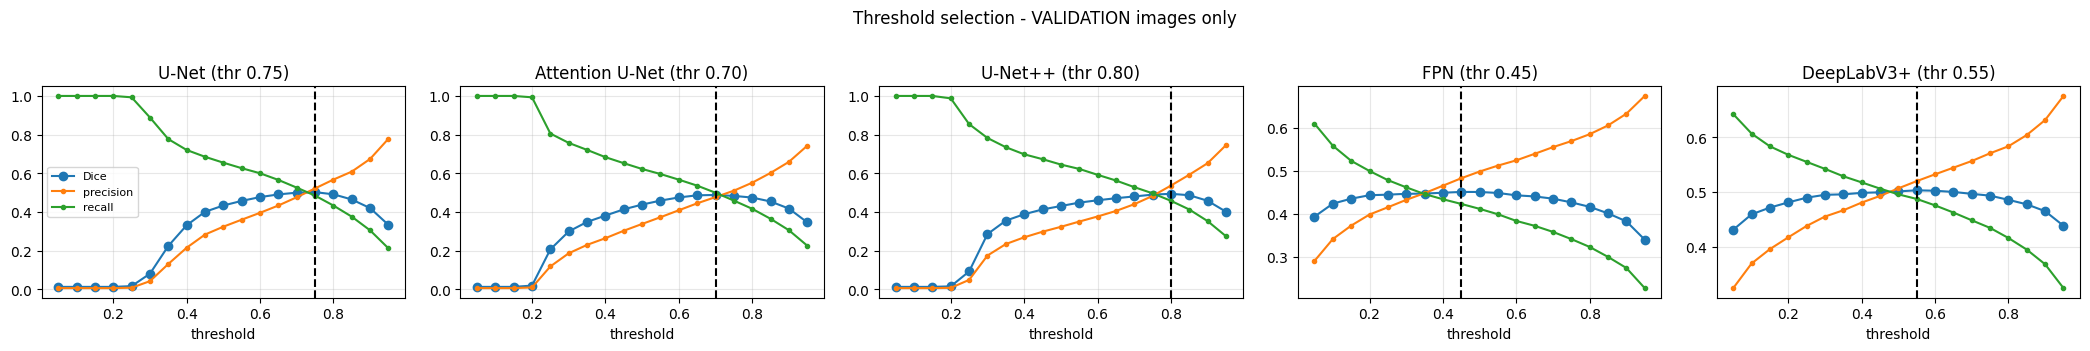

In [14]:
keys = list(CFG.model_names)
fig, axes = plt.subplots(1, len(keys), figsize=(4.2 * len(keys), 3.4), squeeze=False)
for a, k in zip(axes[0], keys):
    sw = RESULTS[k]["sweep"]
    a.plot(sw.threshold, sw.dice, marker="o", label="Dice")
    a.plot(sw.threshold, sw.precision, marker=".", label="precision")
    a.plot(sw.threshold, sw.recall, marker=".", label="recall")
    a.axvline(RESULTS[k]["threshold"], color="k", ls="--")
    a.set_title(f"{RESULTS[k]['label']} (thr {RESULTS[k]['threshold']:.2f})"); a.set_xlabel("threshold"); a.grid(alpha=.3)
axes[0, 0].legend(fontsize=8)
plt.suptitle("Threshold selection - VALIDATION images only", y=1.02)
plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, "figures", f"{PREFIX}_threshold_selection.png"), dpi=130, bbox_inches="tight")
plt.show()

## 15. Training curves for loss and Dice (all models)

Training Dice (stored in each history CSV) is computed on augmented batches with BatchNorm in training mode, so it is only a rough indicator.

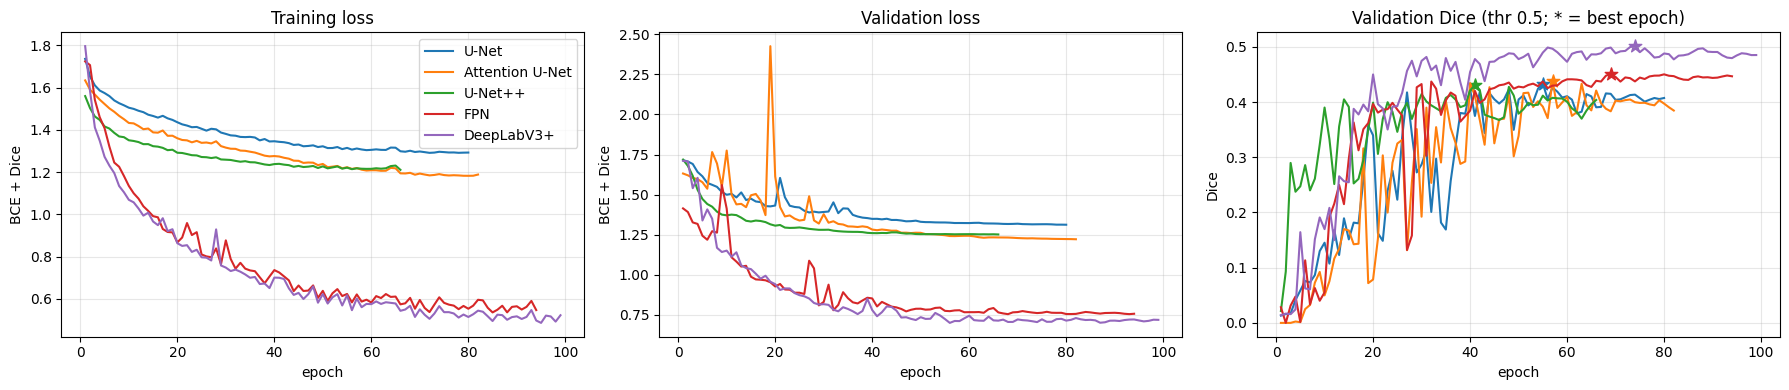

--- U-Net: last epochs ---


,epoch,train_loss,val_loss,train_dice,val_dice,val_iou,val_precision,val_recall,lr,epoch_seconds,elapsed_seconds
77,78,1.2916,1.3126,0.5112,0.4075,0.2559,0.2875,0.6991,0.0,0.6792,68.9650
78,79,1.2924,1.3126,0.5248,0.4056,0.2544,0.2855,0.7002,0.0,0.6761,69.6494
79,80,1.2928,1.3121,0.5122,0.4075,0.2559,0.2876,0.6989,0.0,0.6756,70.3332


--- Attention U-Net: last epochs ---


,epoch,train_loss,val_loss,train_dice,val_dice,val_iou,val_precision,val_recall,lr,epoch_seconds,elapsed_seconds
79,80,1.1828,1.2227,0.5577,0.3973,0.2479,0.2813,0.6764,0.0,0.7681,69.6407
80,81,1.1832,1.2224,0.5691,0.3906,0.2427,0.2722,0.6918,0.0,0.7478,70.3965
81,82,1.1888,1.2215,0.5021,0.3847,0.2382,0.2657,0.6970,0.0,0.7519,71.1567


--- U-Net++: last epochs ---


,epoch,train_loss,val_loss,train_dice,val_dice,val_iou,val_precision,val_recall,lr,epoch_seconds,elapsed_seconds
63,64,1.2287,1.2520,0.4633,0.3846,0.2381,0.2639,0.7086,0.0,1.1127,79.7878
64,65,1.2313,1.2525,0.4788,0.3959,0.2468,0.2769,0.6942,0.0,1.1061,80.9023
65,66,1.2110,1.2514,0.5811,0.4039,0.2530,0.2862,0.6858,0.0,1.1265,82.0495


--- FPN: last epochs ---


,epoch,train_loss,val_loss,train_dice,val_dice,val_iou,val_precision,val_recall,lr,epoch_seconds,elapsed_seconds
91,92,0.5628,0.7566,0.6782,0.4464,0.2873,0.4566,0.4367,0.0,0.5994,62.2066
92,93,0.5908,0.7544,0.5924,0.4482,0.2888,0.4521,0.4444,0.0,0.5566,62.7741
93,94,0.5475,0.7567,0.6745,0.4468,0.2877,0.4700,0.4258,0.0,0.5637,63.3473


--- DeepLabV3+: last epochs ---


,epoch,train_loss,val_loss,train_dice,val_dice,val_iou,val_precision,val_recall,lr,epoch_seconds,elapsed_seconds
96,97,0.5175,0.7123,0.7042,0.4876,0.3224,0.5078,0.4689,0.0,0.9670,121.8839
97,98,0.4930,0.7196,0.7069,0.4852,0.3203,0.5215,0.4536,0.0,0.9607,122.8533
98,99,0.5231,0.7186,0.7137,0.4853,0.3204,0.5228,0.4528,0.0,0.9761,123.8385


In [15]:
fig, ax = plt.subplots(1, 3, figsize=(18, 4))
for k in CFG.model_names:
    h, lab = RESULTS[k]["history"], RESULTS[k]["label"]
    ax[0].plot(h.epoch, h.train_loss, label=lab)
    ax[1].plot(h.epoch, h.val_loss, label=lab)
    ax[2].plot(h.epoch, h.val_dice, label=lab)
    ax[2].scatter([RESULTS[k]["best_epoch"]], [h.val_dice.iloc[RESULTS[k]["best_epoch"] - 1]], marker="*", s=90)
for a, t, yl in zip(ax, ["Training loss", "Validation loss", "Validation Dice (thr 0.5; * = best epoch)"], ["BCE + Dice", "BCE + Dice", "Dice"]):
    a.set_title(t); a.set_xlabel("epoch"); a.set_ylabel(yl); a.grid(alpha=.3)
ax[0].legend()
plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, "figures", f"{PREFIX}_training_curves_all_models.png"), dpi=150)
plt.show()
for k in CFG.model_names:
    print(f"--- {RESULTS[k]['label']}: last epochs ---")
    display(RESULTS[k]["history"].round(4).tail(3))

## 16. Evaluation of all models on the official test set

The test set is loaded here for the first time. Each model uses the threshold selected on validation data.

In [16]:
# The official test set is loaded here for the FIRST time. It is used for final reporting only.
raw_test, test_errors = build_raw_cache(test_pairs, "Loading official test pairs")
test_ids = sorted(raw_test.keys())
for i in test_ids:
    raw_test[i]["enhanced"] = preprocess_resized_rgb(raw_test[i]["image"])
test_imgs = [raw_test[i]["enhanced"] for i in test_ids]
test_gts = [raw_test[i]["mask"] for i in test_ids]

EVAL = {}
for key in CFG.model_names:
    res = RESULTS[key]
    probs = predict_probs(res["model"], test_imgs, CFG.batch_size)
    per_image = evaluate_predictions(probs, test_gts, res["threshold"], test_ids)     # each model uses ITS validation-selected threshold
    summary = summarize(per_image)
    d = model_dir(key)
    per_image.to_csv(os.path.join(d, f"{CFG.lesion_key}_{key}_test_metrics_per_image.csv"), index=False)
    summary.to_csv(os.path.join(d, f"{CFG.lesion_key}_{key}_test_metrics_summary.csv"), index=False)
    EVAL[key] = dict(probs=probs, per_image=per_image, summary=summary)
print(f"Official test set: {len(test_ids)} images evaluated for {len(EVAL)} models (thresholds were chosen on validation data only).")

Loading official test pairs:   0%|          | 0/27 [00:00<?, ?it/s]

Official test set: 27 images evaluated for 5 models (thresholds were chosen on validation data only).


## 17. Metrics tables and confusion-related statistics

Micro-aggregate and per-image tables for all models, pooled TP/FP/FN/TN, counts of empty-ground-truth / empty-prediction images, and a 95% bootstrap confidence interval for micro-Dice obtained by resampling test images (small test sets make rankings uncertain).

Micro-aggregate test metrics (all test pixels pooled; primary).  NOTE: pixel_accuracy is dominated by background and is MISLEADING.


,U-Net,Attention U-Net,U-Net++,FPN,DeepLabV3+
metric,,,,,
dice,0.5600,0.5537,0.5691,0.5329,0.5696
iou,0.3889,0.3828,0.3977,0.3632,0.3982
precision,0.5587,0.5619,0.6527,0.6408,0.6231
recall,0.5613,0.5458,0.5044,0.4561,0.5245
f1,0.5600,0.5537,0.5691,0.5329,0.5696
specificity,0.9952,0.9954,0.9971,0.9972,0.9966
pixel_accuracy,0.9906,0.9906,0.9918,0.9915,0.9915


Per-image mean test metrics (NaN-aware; each image weighs equally):


,U-Net,Attention U-Net,U-Net++,FPN,DeepLabV3+
metric,,,,,
dice,0.4033,0.4157,0.4071,0.4049,0.4011
iou,0.2770,0.2870,0.2823,0.2769,0.2758
precision,0.4461,0.4192,0.5310,0.4981,0.4989
recall,0.4201,0.4616,0.3698,0.3788,0.3926
f1,0.4033,0.4157,0.4071,0.4049,0.4011
specificity,0.9951,0.9954,0.9971,0.9972,0.9965
pixel_accuracy,0.9906,0.9906,0.9918,0.9915,0.9915


,model,TP,FP,FN,TN,images_empty_GT,images_empty_pred,GT_present_but_nothing_predicted,pred_but_empty_GT,micro_dice_ci95_low,micro_dice_ci95_high
0,U-Net,10605,8375,8290,1742202,0,1,1,0,0.4721,0.6084
1,Attention U-Net,10312,8041,8583,1742536,0,0,0,0,0.4738,0.5970
2,U-Net++,9531,5071,9364,1745506,0,1,1,0,0.4791,0.6109
3,FPN,8618,4831,10277,1745746,0,1,1,0,0.4702,0.5646
4,DeepLabV3+,9911,5995,8984,1744582,0,1,1,0,0.4794,0.6088


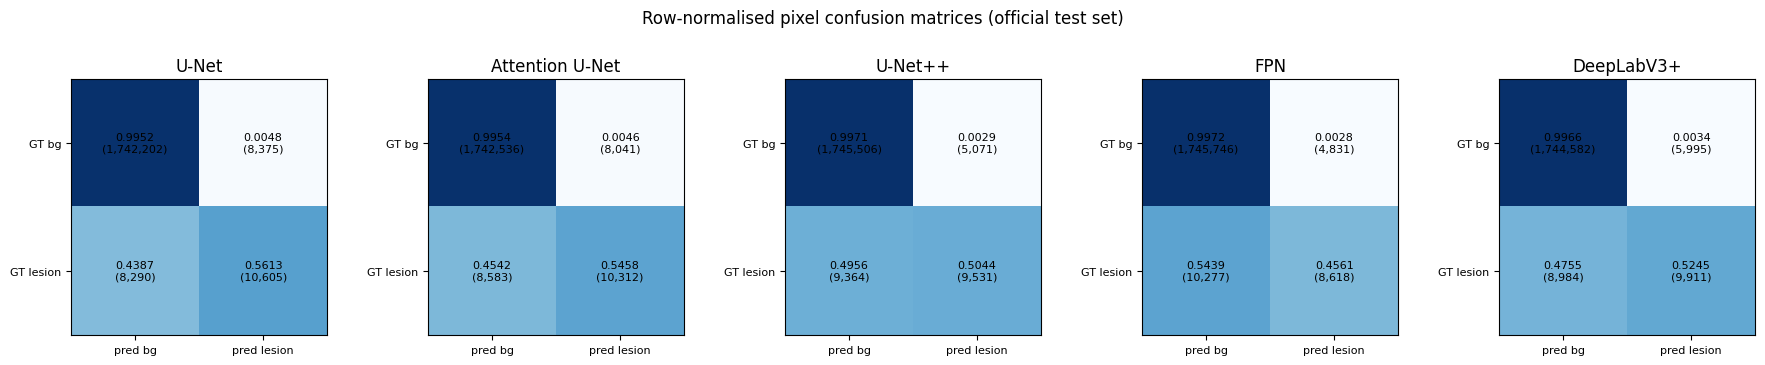

In [17]:
metric_cols = METRIC_KEYS
label_of = {k: MODEL_ZOO[k]["label"] for k in CFG.model_names}
micro_tbl = pd.DataFrame({label_of[k]: EVAL[k]["summary"].set_index("metric").micro_aggregate for k in CFG.model_names}).loc[metric_cols]
mean_tbl = pd.DataFrame({label_of[k]: EVAL[k]["summary"].set_index("metric").per_image_mean for k in CFG.model_names}).loc[metric_cols]
print("Micro-aggregate test metrics (all test pixels pooled; primary).  NOTE: pixel_accuracy is dominated by background and is MISLEADING.")
display(micro_tbl.round(4))
print("Per-image mean test metrics (NaN-aware; each image weighs equally):")
display(mean_tbl.round(4))
micro_tbl.to_csv(os.path.join(OUT_DIR, f"{PREFIX}_test_metrics_micro_all_models.csv"))
mean_tbl.to_csv(os.path.join(OUT_DIR, f"{PREFIX}_test_metrics_per_image_mean_all_models.csv"))


def bootstrap_dice_ci(df, n_boot=1000, seed=0):
    """95% percentile bootstrap CI of the micro-Dice, resampling TEST IMAGES (shows how uncertain a tiny test set is)."""
    rng = np.random.RandomState(seed)
    tp, fp, fn = df.tp.values.astype(float), df.fp.values.astype(float), df.fn.values.astype(float)
    vals = []
    for _ in range(n_boot):
        s = rng.randint(0, len(df), len(df))
        den = 2 * tp[s].sum() + fp[s].sum() + fn[s].sum()
        vals.append(2 * tp[s].sum() / den if den > 0 else 1.0)
    return float(np.percentile(vals, 2.5)), float(np.percentile(vals, 97.5))


conf_rows = []
for k in CFG.model_names:
    pi = EVAL[k]["per_image"]
    lo, hi = bootstrap_dice_ci(pi)
    conf_rows.append(dict(model=label_of[k], TP=int(pi.tp.sum()), FP=int(pi.fp.sum()), FN=int(pi.fn.sum()), TN=int(pi.tn.sum()),
                          images_empty_GT=int((pi.gt_pixels == 0).sum()), images_empty_pred=int((pi.pred_pixels == 0).sum()),
                          GT_present_but_nothing_predicted=int(((pi.gt_pixels > 0) & (pi.pred_pixels == 0)).sum()),
                          pred_but_empty_GT=int(((pi.gt_pixels == 0) & (pi.pred_pixels > 0)).sum()),
                          micro_dice_ci95_low=lo, micro_dice_ci95_high=hi))
conf_tbl = pd.DataFrame(conf_rows)
display(conf_tbl.round(4))
conf_tbl.to_csv(os.path.join(OUT_DIR, f"{PREFIX}_test_confusion_all_models.csv"), index=False)

fig, axes = plt.subplots(1, len(CFG.model_names), figsize=(3.6 * len(CFG.model_names), 3.4), squeeze=False)
for a, k in zip(axes[0], CFG.model_names):
    pi = EVAL[k]["per_image"]
    cm = np.array([[pi.tn.sum(), pi.fp.sum()], [pi.fn.sum(), pi.tp.sum()]], dtype=float)
    norm = cm / cm.sum(axis=1, keepdims=True)
    a.imshow(norm, cmap="Blues", vmin=0, vmax=1)
    for (r, c), v in np.ndenumerate(norm):
        a.text(c, r, f"{v:.4f}\n({int(cm[r, c]):,})", ha="center", va="center", fontsize=8)
    a.set_xticks([0, 1]); a.set_xticklabels(["pred bg", "pred lesion"], fontsize=8)
    a.set_yticks([0, 1]); a.set_yticklabels(["GT bg", "GT lesion"], fontsize=8); a.set_title(label_of[k])
plt.suptitle("Row-normalised pixel confusion matrices (official test set)", y=1.03)
plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, "figures", f"{PREFIX}_test_confusion_all_models.png"), dpi=130, bbox_inches="tight")
plt.show()

## 18. Model comparison, best-model selection and ground truth versus prediction

The best model is chosen by **validation Dice**. The table also shows validation and test ranks side by side. Visualizations: (A) the best model on every test image - original, ground-truth mask, predicted mask, predicted overlay; (B) all five models side by side.

Selected best model (highest validation Dice): DeepLabV3+ (deeplabv3plus) - validation Dice 0.5033


,model,key,encoder,params_M,epochs_run,best_epoch,train_min,threshold,val_dice,test_dice_micro,test_dice_ci95_low,test_dice_ci95_high,test_dice_per_image_mean,test_iou_micro,test_precision_micro,test_recall_micro,test_specificity_micro,val_rank,test_rank_by_dice,selected_best
0,U-Net,unet,resnet34 (imagenet),24.44,80,55,1.17,0.75,0.5026,0.5600,0.4721,0.6084,0.4033,0.3889,0.5587,0.5613,0.9952,2,3,False
1,Attention U-Net,attention_unet,resnet34 (imagenet),24.57,82,57,1.19,0.70,0.4881,0.5537,0.4738,0.5970,0.4157,0.3828,0.5619,0.5458,0.9954,4,4,False
2,U-Net++,unetplusplus,resnet34 (imagenet),25.77,66,41,1.37,0.80,0.4940,0.5691,0.4791,0.6109,0.4071,0.3977,0.6527,0.5044,0.9971,3,2,False
3,FPN,fpn,resnet34 (imagenet),22.29,94,69,1.06,0.45,0.4509,0.5329,0.4702,0.5646,0.4049,0.3632,0.6408,0.4561,0.9972,5,5,False
4,DeepLabV3+,deeplabv3plus,resnet50 (imagenet),40.35,99,74,2.06,0.55,0.5033,0.5696,0.4794,0.6088,0.4011,0.3982,0.6231,0.5245,0.9966,1,1,True


Differences between models are often smaller than the bootstrap confidence intervals - read the ranking cautiously.


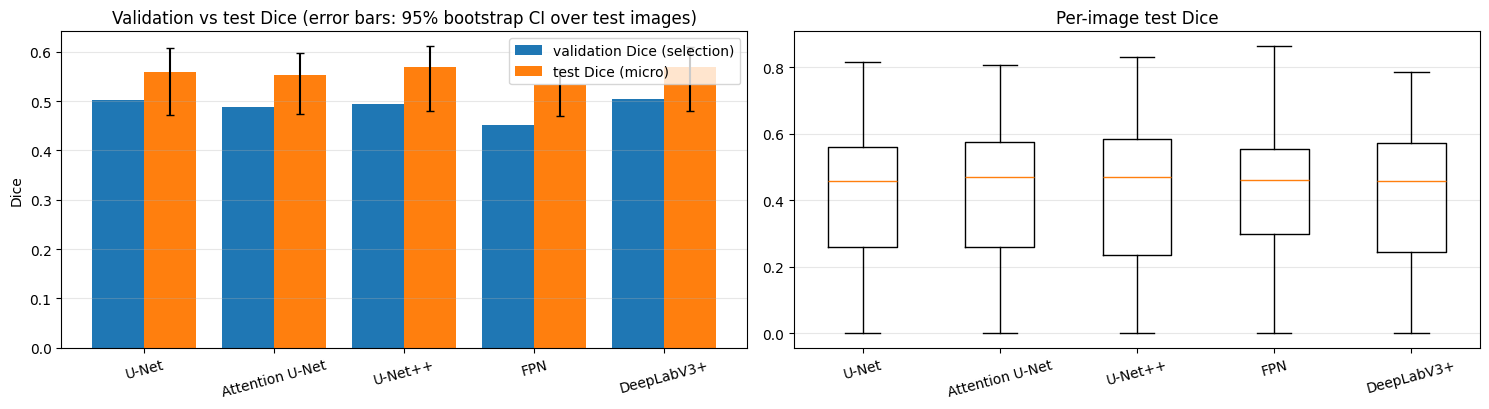

In [18]:
# ---- Best-model selection uses VALIDATION Dice (at each model's validation-selected threshold). Never the test set. ----
BEST_KEY = max(CFG.model_names, key=lambda k: RESULTS[k]["val_dice_at_threshold"])
print(f"Selected best model (highest validation Dice): {MODEL_ZOO[BEST_KEY]['label']} ({BEST_KEY}) "
      f"- validation Dice {RESULTS[BEST_KEY]['val_dice_at_threshold']:.4f}")


def build_comparison(timing=None):
    rows = []
    for k in CFG.model_names:
        r, e = RESULTS[k], EVAL[k]
        sm = e["summary"].set_index("metric")
        lo, hi = bootstrap_dice_ci(e["per_image"])
        row = dict(model=MODEL_ZOO[k]["label"], key=k, encoder=f"{MODEL_ZOO[k]['kwargs']['encoder_name']} ({r['encoder_weights']})",
                   params_M=round(r["n_params"] / 1e6, 2), epochs_run=r["epochs_run"], best_epoch=r["best_epoch"],
                   train_min=round(r["train_seconds"] / 60, 2), threshold=r["threshold"], val_dice=r["val_dice_at_threshold"],
                   test_dice_micro=sm.loc["dice", "micro_aggregate"], test_dice_ci95_low=lo, test_dice_ci95_high=hi,
                   test_dice_per_image_mean=sm.loc["dice", "per_image_mean"], test_iou_micro=sm.loc["iou", "micro_aggregate"],
                   test_precision_micro=sm.loc["precision", "micro_aggregate"], test_recall_micro=sm.loc["recall", "micro_aggregate"],
                   test_specificity_micro=sm.loc["specificity", "micro_aggregate"])
        if timing is not None:
            row["infer_ms_model_only"] = timing[k]["model_only_mean"]
            row["infer_ms_end_to_end"] = timing[k]["end_to_end_mean"]
        rows.append(row)
    df = pd.DataFrame(rows)
    df["val_rank"] = df.val_dice.rank(ascending=False, method="min").astype(int)
    df["test_rank_by_dice"] = df.test_dice_micro.rank(ascending=False, method="min").astype(int)
    df["selected_best"] = df.key == BEST_KEY
    return df


comparison = build_comparison()
display(comparison.round(4))
test_best = comparison.loc[comparison.test_dice_micro.idxmax(), "key"]
if test_best != BEST_KEY:
    print(f"NOTE: {MODEL_ZOO[test_best]['label']} has the highest TEST Dice, but the choice of {MODEL_ZOO[BEST_KEY]['label']} was made on validation "
          "data only. Picking the model by test score would leak the test set into model selection.")
print("Differences between models are often smaller than the bootstrap confidence intervals - read the ranking cautiously.")

labels = [label_of[k] for k in CFG.model_names]
x = np.arange(len(labels))
fig, ax = plt.subplots(1, 2, figsize=(15, 4.2))
ax[0].bar(x - 0.2, comparison.val_dice, 0.4, label="validation Dice (selection)")
ax[0].bar(x + 0.2, comparison.test_dice_micro, 0.4, label="test Dice (micro)",
          yerr=[comparison.test_dice_micro - comparison.test_dice_ci95_low, comparison.test_dice_ci95_high - comparison.test_dice_micro], capsize=3)
ax[0].set_xticks(x); ax[0].set_xticklabels(labels, rotation=15); ax[0].set_ylabel("Dice"); ax[0].legend(); ax[0].grid(axis="y", alpha=.3)
ax[0].set_title("Validation vs test Dice (error bars: 95% bootstrap CI over test images)")
ax[1].boxplot([EVAL[k]["per_image"].dice.dropna().values for k in CFG.model_names])
ax[1].set_xticklabels(labels)
ax[1].set_title("Per-image test Dice"); ax[1].grid(axis="y", alpha=.3); plt.setp(ax[1].get_xticklabels(), rotation=15)
plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, "figures", f"{PREFIX}_model_comparison.png"), dpi=150)
plt.show()

In [19]:
def pred_mask(key, idx):
    return (EVAL[key]["probs"][idx] >= RESULTS[key]["threshold"]).astype(np.uint8)


legend = [Patch(color=np.array(CFG.overlay_color_rgb) / 255, label=f"predicted {CFG.lesion_key}")]
best_dice_by_id = dict(zip(EVAL[BEST_KEY]["per_image"].image_id, EVAL[BEST_KEY]["per_image"].dice))
print(f"A) Best model ({MODEL_ZOO[BEST_KEY]['label']}) on every test image: original | ground truth | prediction | overlay")


def show_best(chunk=4):
    for s in range(0, len(test_ids), chunk):
        sub = list(range(s, min(s + chunk, len(test_ids))))
        fig, axes = plt.subplots(len(sub), 4, figsize=(16, 4 * len(sub)), squeeze=False)
        for r, idx in enumerate(sub):
            i, d, pm = test_ids[idx], raw_test[test_ids[idx]], pred_mask(BEST_KEY, idx)
            axes[r, 0].imshow(d["image"]);                                axes[r, 0].set_title(f"IDRiD_{i:02d} - original")
            axes[r, 1].imshow(d["mask"], cmap="gray", vmin=0, vmax=1);    axes[r, 1].set_title(f"Ground truth ({int(d['mask'].sum())} px)")
            axes[r, 2].imshow(pm, cmap="gray", vmin=0, vmax=1);           axes[r, 2].set_title(f"{MODEL_ZOO[BEST_KEY]['label']} ({int(pm.sum())} px) Dice={best_dice_by_id[i]:.3f}")
            axes[r, 3].imshow(overlay_mask(d["image"], pm, CFG.overlay_color_rgb)); axes[r, 3].set_title("Predicted overlay")
            axes[r, 3].legend(handles=legend, loc="lower right", fontsize=8)
            for a in axes[r]:
                a.axis("off")
        plt.tight_layout()
        plt.savefig(os.path.join(OUT_DIR, "figures", f"{PREFIX}_best_model_test_gt_vs_pred_{s // chunk + 1:02d}.png"), dpi=110)
        plt.show()


show_best()

print("B) All models side by side: original | ground truth | one column per model (per-image Dice in the title)")


def show_all_models(chunk=4):
    for s in range(0, len(test_ids), chunk):
        sub = list(range(s, min(s + chunk, len(test_ids))))
        ncol = 2 + len(CFG.model_names)
        fig, axes = plt.subplots(len(sub), ncol, figsize=(3.3 * ncol, 3.4 * len(sub)), squeeze=False)
        for r, idx in enumerate(sub):
            i, d = test_ids[idx], raw_test[test_ids[idx]]
            axes[r, 0].imshow(d["image"]); axes[r, 0].set_title(f"IDRiD_{i:02d}", fontsize=9)
            axes[r, 1].imshow(d["mask"], cmap="gray", vmin=0, vmax=1); axes[r, 1].set_title("Ground truth", fontsize=9)
            for c, k in enumerate(CFG.model_names):
                axes[r, 2 + c].imshow(pred_mask(k, idx), cmap="gray", vmin=0, vmax=1)
                axes[r, 2 + c].set_title(f"{label_of[k]}  Dice={EVAL[k]['per_image'].dice.iloc[idx]:.2f}", fontsize=9)
            for a in axes[r]:
                a.axis("off")
        plt.tight_layout()
        plt.savefig(os.path.join(OUT_DIR, "figures", f"{PREFIX}_all_models_test_{s // chunk + 1:02d}.png"), dpi=100)
        plt.show()


show_all_models()

Output hidden; open in https://colab.research.google.com to view.

## 19. Binary predicted masks and overlays (saved as PNG)

For every model and every test image: a binary mask PNG at original resolution and an overlay PNG (model resolution) in the lesion's overlay colour. An error map (TP green, FP red, FN blue) of the best model is shown for a few images.

           U-Net: saved 27 binary masks + 27 overlays -> /content/drive/MyDrive/Research/A. Segmentation/outputs/HE_5models/unet
 Attention U-Net: saved 27 binary masks + 27 overlays -> /content/drive/MyDrive/Research/A. Segmentation/outputs/HE_5models/attention_unet
         U-Net++: saved 27 binary masks + 27 overlays -> /content/drive/MyDrive/Research/A. Segmentation/outputs/HE_5models/unetplusplus
             FPN: saved 27 binary masks + 27 overlays -> /content/drive/MyDrive/Research/A. Segmentation/outputs/HE_5models/fpn
      DeepLabV3+: saved 27 binary masks + 27 overlays -> /content/drive/MyDrive/Research/A. Segmentation/outputs/HE_5models/deeplabv3plus


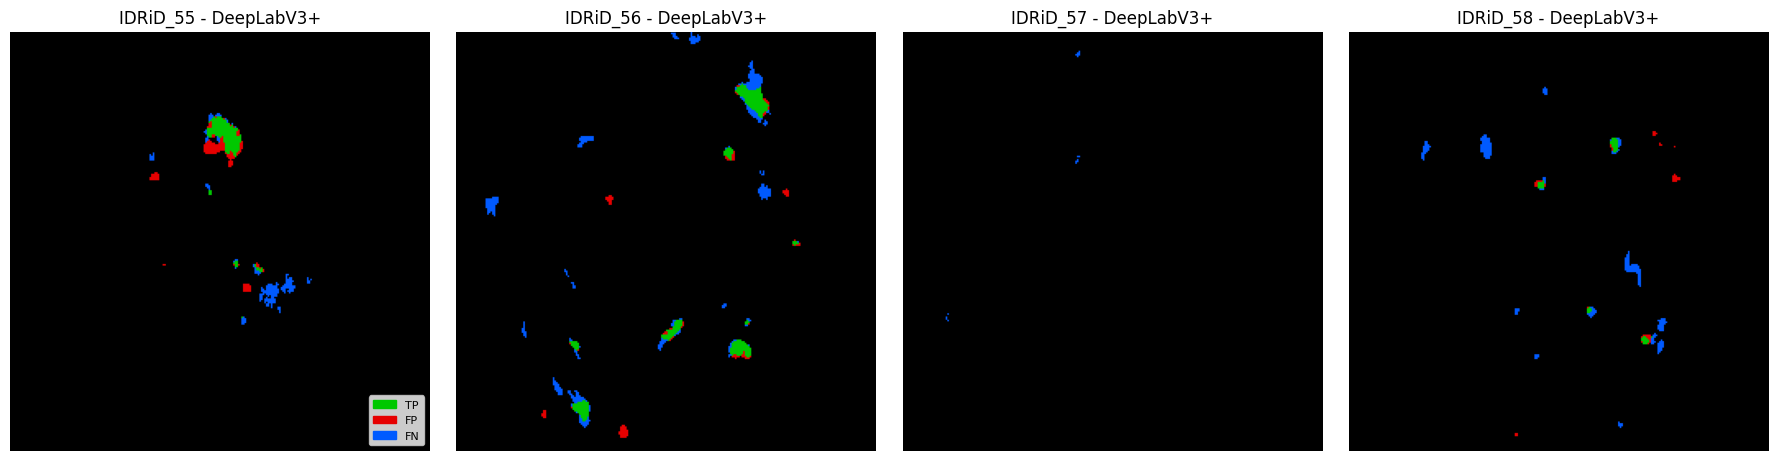

In [20]:
# Binary masks: ORIGINAL image resolution (probability map up-sampled bilinearly, then thresholded). Overlays: model resolution.
for key in CFG.model_names:
    d = model_dir(key)
    for idx, i in enumerate(test_ids):
        h, w = raw_test[i]["orig_hw"]
        full = (cv2.resize(EVAL[key]["probs"][idx], (w, h), interpolation=cv2.INTER_LINEAR) >= RESULTS[key]["threshold"]).astype(np.uint8) * 255
        cv2.imwrite(os.path.join(d, "pred_masks", f"IDRiD_{i:02d}{CFG.mask_suffix}_pred.png"), full)
        ov = overlay_mask(raw_test[i]["image"], pred_mask(key, idx), CFG.overlay_color_rgb)
        cv2.imwrite(os.path.join(d, "overlays", f"IDRiD_{i:02d}{CFG.mask_suffix}_overlay.png"), cv2.cvtColor(ov, cv2.COLOR_RGB2BGR))
    print(f"{label_of[key]:>16}: saved {len(test_ids)} binary masks + {len(test_ids)} overlays -> {d}")

# Error maps of the BEST model (TP green, FP red, FN blue) for the first few test images
show_idx = list(range(min(4, len(test_ids))))
fig, axes = plt.subplots(1, len(show_idx), figsize=(4.5 * len(show_idx), 4.5), squeeze=False)
for a, idx in zip(axes[0], show_idx):
    gt, pr = raw_test[test_ids[idx]]["mask"].astype(bool), pred_mask(BEST_KEY, idx).astype(bool)
    err = np.zeros((*gt.shape, 3), np.uint8)
    err[gt & pr] = (0, 200, 0); err[~gt & pr] = (230, 0, 0); err[gt & ~pr] = (0, 90, 255)
    a.imshow(err); a.set_title(f"IDRiD_{test_ids[idx]:02d} - {label_of[BEST_KEY]}"); a.axis("off")
axes[0, 0].legend(handles=[Patch(color="#00c800", label="TP"), Patch(color="#e60000", label="FP"), Patch(color="#005aff", label="FN")],
                  loc="lower right", fontsize=8)
plt.tight_layout(); plt.show()

## 20. Inference-time measurement (all models)

Batch size 1, warm-up excluded, GPU synchronised: forward pass only, and end-to-end tensor pipeline (without image decoding, resizing and CLAHE). Numbers are specific to the hardware printed below.

In [21]:
def time_inference(model, thr, images_uint8, n_warmup=10):
    """Batch size 1. 'model_only': synchronised forward pass. 'end_to_end': normalise + host->device copy + forward +
    sigmoid + threshold + device->host copy. Image decoding, resizing and CLAHE are NOT included."""
    model.eval()
    sync = torch.cuda.synchronize if device.type == "cuda" else (lambda: None)
    x0 = to_tensor(images_uint8[0])[None].to(device)
    t_model, t_e2e = [], []
    with torch.no_grad():
        for _ in range(n_warmup):
            model(x0)
        sync()
        for im in images_uint8:
            t0 = time.perf_counter()
            x = to_tensor(im)[None].to(device)
            sync(); t1 = time.perf_counter()
            y = model(x)
            sync(); t2 = time.perf_counter()
            _ = (torch.sigmoid(y)[0, 0] >= thr).cpu().numpy()
            t3 = time.perf_counter()
            t_model.append((t2 - t1) * 1000); t_e2e.append((t3 - t0) * 1000)
    return np.array(t_model), np.array(t_e2e)


hw_name = torch.cuda.get_device_name(0) if device.type == "cuda" else platform.processor() or "CPU"
TIMING_RES, trows = {}, []
for key in CFG.model_names:
    tm, te = time_inference(RESULTS[key]["model"], RESULTS[key]["threshold"], test_imgs)
    TIMING_RES[key] = dict(model_only_mean=float(tm.mean()), end_to_end_mean=float(te.mean()))
    trows.append(dict(model=label_of[key], model_only_ms_mean=tm.mean(), model_only_ms_std=tm.std(), model_only_ms_p95=np.percentile(tm, 95),
                      end_to_end_ms_mean=te.mean(), end_to_end_ms_std=te.std(), end_to_end_ms_p95=np.percentile(te, 95)))
timing_tbl = pd.DataFrame(trows).assign(hardware=hw_name, image_size=CFG.img_size, batch_size=1, n_images=len(test_imgs))
print(f"Hardware: {hw_name} | {CFG.img_size}x{CFG.img_size} | batch size 1 | {len(test_imgs)} images | AMP off")
display(timing_tbl.round(2))
timing_tbl.to_csv(os.path.join(OUT_DIR, f"{PREFIX}_inference_timing_all_models.csv"), index=False)

Hardware: Tesla T4 | 256x256 | batch size 1 | 27 images | AMP off


,model,model_only_ms_mean,model_only_ms_std,model_only_ms_p95,end_to_end_ms_mean,end_to_end_ms_std,end_to_end_ms_p95,hardware,image_size,batch_size,n_images
0,U-Net,14.03,1.73,17.20,15.93,1.85,19.15,Tesla T4,256,1,27
1,Attention U-Net,13.62,0.25,14.07,15.43,0.46,16.45,Tesla T4,256,1,27
2,U-Net++,25.05,0.44,25.82,27.00,0.61,28.37,Tesla T4,256,1,27
3,FPN,9.47,0.17,9.78,11.10,0.20,11.52,Tesla T4,256,1,27
4,DeepLabV3+,19.61,0.82,21.08,21.35,0.96,23.00,Tesla T4,256,1,27


## 21. Saving model weights and inference metadata

Each model gets its own folder (`outputs/<LESION>_5models/<model>/`) with best weights (`.pth` state_dict), metadata JSON (architecture class and constructor arguments, input size, colour order, preprocessing order, CLAHE settings, normalisation, selected threshold, overlay colour, training summary, inference timing, test metrics, library versions), training-history CSV, threshold sweep, test-metric CSVs, predicted masks, overlays and an optional TorchScript file. The **selected best model** is copied to `best_model/` - that folder is what the API should load. The cell after the save re-loads it from disk and defines `predict_full_resolution(...)`, the exact preprocessing -> inference -> threshold -> resize-back routine for the API, and verifies that it reproduces the saved mask.

In [22]:
import shutil


def make_metadata(key):
    r, e, z = RESULTS[key], EVAL[key], MODEL_ZOO[key]
    micro = e["summary"].set_index("metric").micro_aggregate.to_dict()
    return {
        "schema_version": 1,
        "research_use_only": True,
        "disclaimer": "Research prototype trained on IDRiD. Not a medical device; not for clinical diagnosis.",
        "lesion": {"key": CFG.lesion_key, "name": CFG.lesion_name, "overlay_color_rgb": list(CFG.overlay_color_rgb)},
        "model": {"key": key, "architecture": z["label"], "class_name": z["cls"].__name__, "kwargs": z["kwargs"],
                  "pretrained_encoder_weights": r["encoder_weights"], "num_classes": 1,
                  "output": "raw logits; apply sigmoid then threshold", "n_parameters": int(r["n_params"])},
        "input": {"image_size": [CFG.img_size, CFG.img_size], "channel_order": "RGB",
                  "preprocessing_order": ["load RGB", f"resize to {CFG.img_size}x{CFG.img_size} (cv2.INTER_AREA)",
                                          "CLAHE on LAB L-channel" if CFG.use_clahe else "no enhancement",
                                          "divide by 255", "subtract mean / divide by std", "HWC -> CHW"],
                  "clahe": {"enabled": CFG.use_clahe, "clip_limit": CFG.clahe_clip, "tile_grid": [CFG.clahe_tile, CFG.clahe_tile],
                            "colour_space": "LAB (L channel only)"},
                  "normalization": {"mean": list(CFG.mean), "std": list(CFG.std)}},
        "inference": {"threshold": float(r["threshold"]), "threshold_selected_on": "validation set (micro-Dice), never on test data",
                      "output_mask_resizing": "bilinear-upsample probability map to original size, then threshold"},
        "training": {"seed": CFG.seed, "epochs_run": int(r["epochs_run"]), "best_epoch": int(r["best_epoch"]),
                     "best_val_dice_at_0.5": float(r["best_val_dice_at_0_5"]), "val_dice_at_selected_threshold": float(r["val_dice_at_threshold"]),
                     "batch_size": CFG.batch_size, "lr": CFG.lr, "loss": f"BCE(pos_weight={r['pos_weight']:.3f}) + soft Dice",
                     "training_seconds": float(r["train_seconds"]), "n_train_images": len(train_ids), "n_val_images": len(val_ids),
                     "smoke_test": CFG.smoke_test},
        "selected_as_best_model_for_lesion": bool(key == BEST_KEY),
        "inference_ms_per_image": TIMING_RES[key],
        "test_metrics_micro_aggregate": {k: (None if (v != v) else float(v)) for k, v in micro.items() if k in METRIC_KEYS},
        "environment": {"torch": torch.__version__, "torchvision": torchvision.__version__, "opencv": cv2.__version__},
        "files": {"weights": f"{CFG.lesion_key}_{key}_best.pth"},
    }


for key in CFG.model_names:
    d = model_dir(key)
    meta_path = os.path.join(d, f"{CFG.lesion_key}_{key}_model_metadata.json")
    with open(meta_path, "w") as f:
        json.dump(make_metadata(key), f, indent=2)
    try:                                       # optional TorchScript export (loadable without the class definitions)
        m_cpu = copy.deepcopy(RESULTS[key]["model"]).cpu().eval()
        ts = torch.jit.trace(m_cpu, torch.randn(1, 3, CFG.img_size, CFG.img_size), check_trace=False)
        ts.save(os.path.join(d, f"{CFG.lesion_key}_{key}_torchscript.pt"))
    except Exception as e:
        print(f"[INFO] TorchScript export skipped for {key}: {e!r}")
    print(f"Saved weights + metadata for {label_of[key]} -> {d}")

# ---- copy the selected best model into a dedicated folder: this is what the API should load ----
BEST_DIR = os.path.join(OUT_DIR, "best_model")
os.makedirs(BEST_DIR, exist_ok=True)
src = model_dir(BEST_KEY)
best_weights = f"{CFG.lesion_key}_BEST_{BEST_KEY}.pth"
shutil.copy(os.path.join(src, f"{CFG.lesion_key}_{BEST_KEY}_best.pth"), os.path.join(BEST_DIR, best_weights))
ts_src = os.path.join(src, f"{CFG.lesion_key}_{BEST_KEY}_torchscript.pt")
if os.path.exists(ts_src):
    shutil.copy(ts_src, os.path.join(BEST_DIR, f"{CFG.lesion_key}_BEST_{BEST_KEY}_torchscript.pt"))
best_meta = make_metadata(BEST_KEY)
best_meta["files"]["weights"] = best_weights
META_PATH = os.path.join(BEST_DIR, f"{CFG.lesion_key}_BEST_model_metadata.json")
with open(META_PATH, "w") as f:
    json.dump(best_meta, f, indent=2)
print(f"\nBEST MODEL for {CFG.lesion_key}: {label_of[BEST_KEY]} -> {BEST_DIR}")

/tmp/ipykernel_1130/529222355.py:88: TracerWarning: Converting a tensor to a Python boolean might cause the trace to be incorrect. We can't record the data flow of Python values, so this value will be treated as a constant in the future. This means that the trace might not generalize to other inputs!
  if out.shape[-2:] != x.shape[-2:]:


Saved weights + metadata for U-Net -> /content/drive/MyDrive/Research/A. Segmentation/outputs/HE_5models/unet


/tmp/ipykernel_1130/529222355.py:146: TracerWarning: Converting a tensor to a Python boolean might cause the trace to be incorrect. We can't record the data flow of Python values, so this value will be treated as a constant in the future. This means that the trace might not generalize to other inputs!
  if out.shape[-2:] != x.shape[-2:]:


Saved weights + metadata for Attention U-Net -> /content/drive/MyDrive/Research/A. Segmentation/outputs/HE_5models/attention_unet


/tmp/ipykernel_1130/529222355.py:187: TracerWarning: Converting a tensor to a Python boolean might cause the trace to be incorrect. We can't record the data flow of Python values, so this value will be treated as a constant in the future. This means that the trace might not generalize to other inputs!
  if out.shape[-2:] != x.shape[-2:]:


Saved weights + metadata for U-Net++ -> /content/drive/MyDrive/Research/A. Segmentation/outputs/HE_5models/unetplusplus
Saved weights + metadata for FPN -> /content/drive/MyDrive/Research/A. Segmentation/outputs/HE_5models/fpn
Saved weights + metadata for DeepLabV3+ -> /content/drive/MyDrive/Research/A. Segmentation/outputs/HE_5models/deeplabv3plus

BEST MODEL for HE: DeepLabV3+ -> /content/drive/MyDrive/Research/A. Segmentation/outputs/HE_5models/best_model


In [23]:
# Re-load the BEST model from disk exactly as a separate inference API would, and verify identical predictions.
with open(META_PATH) as f:
    meta = json.load(f)

fresh = build_model(meta["model"]["key"], pretrained=False).to(device)      # API: instantiate meta["model"]["class_name"](**kwargs)
fresh.load_state_dict(torch.load(os.path.join(BEST_DIR, meta["files"]["weights"]), map_location=device))
fresh.eval()


def predict_full_resolution(net, img_rgb, meta):
    """img_rgb: uint8 RGB array of ANY size -> binary uint8 mask {0,255} of the same size (what the React API should return)."""
    size = meta["input"]["image_size"][0]
    h, w = img_rgb.shape[:2]
    x = cv2.resize(img_rgb, (size, size), interpolation=cv2.INTER_AREA)
    if meta["input"]["clahe"]["enabled"]:
        lab = cv2.cvtColor(x, cv2.COLOR_RGB2LAB)
        t = meta["input"]["clahe"]["tile_grid"]
        lab[..., 0] = cv2.createCLAHE(clipLimit=meta["input"]["clahe"]["clip_limit"], tileGridSize=tuple(t)).apply(lab[..., 0])
        x = cv2.cvtColor(lab, cv2.COLOR_LAB2RGB)
    mean, std = np.array(meta["input"]["normalization"]["mean"], np.float32), np.array(meta["input"]["normalization"]["std"], np.float32)
    x = torch.from_numpy(((x.astype(np.float32) / 255 - mean) / std).transpose(2, 0, 1).copy())[None].to(next(net.parameters()).device)
    with torch.no_grad():
        prob = torch.sigmoid(net(x).float())[0, 0].cpu().numpy()
    prob = cv2.resize(prob, (w, h), interpolation=cv2.INTER_LINEAR)
    return (prob >= meta["inference"]["threshold"]).astype(np.uint8) * 255


probe_id = test_ids[0]
probe_row = test_pairs[test_pairs.image_id == probe_id].iloc[0]
probe_img = read_rgb(probe_row.image_path)
mask_api = predict_full_resolution(fresh, probe_img, meta)
saved_png = cv2.imread(os.path.join(model_dir(BEST_KEY), "pred_masks", f"IDRiD_{probe_id:02d}{CFG.mask_suffix}_pred.png"), cv2.IMREAD_UNCHANGED)
print("API-style mask shape:", mask_api.shape, "| original image shape:", probe_img.shape[:2])
print("identical to the mask saved during evaluation:", bool(np.array_equal(mask_api, saved_png)),
      "| differing pixels:", int((mask_api != saved_png).sum()))

API-style mask shape: (2848, 4288) | original image shape: (2848, 4288)
identical to the mask saved during evaluation: True | differing pixels: 0


## 22. Final results summary and research limitations

In [24]:
final = build_comparison(TIMING_RES)
final.to_csv(os.path.join(OUT_DIR, f"{PREFIX}_model_comparison.csv"), index=False)
display(final.round(4))
b = final[final.key == BEST_KEY].iloc[0]
print(f"\nSELECTED (validation Dice): {b.model} | threshold {b.threshold:.2f} | validation Dice {b.val_dice:.4f} | "
      f"test micro-Dice {b.test_dice_micro:.4f} (95% bootstrap CI {b.test_dice_ci95_low:.4f}-{b.test_dice_ci95_high:.4f}) | "
      f"{b.infer_ms_model_only:.1f} ms/image (model only)")
print("Files for the API: ", BEST_DIR)
if CFG.smoke_test:
    print("\nSMOKE TEST RUN: these numbers only prove that the pipeline executes end-to-end for all five models. They are NOT research results.")
    print("Set CFG.smoke_test = False, restart the runtime and run the notebook again for the real experiment.")

,model,key,encoder,params_M,epochs_run,best_epoch,train_min,threshold,val_dice,test_dice_micro,...,test_dice_per_image_mean,test_iou_micro,test_precision_micro,test_recall_micro,test_specificity_micro,infer_ms_model_only,infer_ms_end_to_end,val_rank,test_rank_by_dice,selected_best
0,U-Net,unet,resnet34 (imagenet),24.44,80,55,1.17,0.75,0.5026,0.5600,...,0.4033,0.3889,0.5587,0.5613,0.9952,14.0298,15.9313,2,3,False
1,Attention U-Net,attention_unet,resnet34 (imagenet),24.57,82,57,1.19,0.70,0.4881,0.5537,...,0.4157,0.3828,0.5619,0.5458,0.9954,13.6180,15.4337,4,4,False
2,U-Net++,unetplusplus,resnet34 (imagenet),25.77,66,41,1.37,0.80,0.4940,0.5691,...,0.4071,0.3977,0.6527,0.5044,0.9971,25.0480,27.0021,3,2,False
3,FPN,fpn,resnet34 (imagenet),22.29,94,69,1.06,0.45,0.4509,0.5329,...,0.4049,0.3632,0.6408,0.4561,0.9972,9.4705,11.0988,5,5,False
4,DeepLabV3+,deeplabv3plus,resnet50 (imagenet),40.35,99,74,2.06,0.55,0.5033,0.5696,...,0.4011,0.3982,0.6231,0.5245,0.9966,19.6127,21.3522,1,1,True



SELECTED (validation Dice): DeepLabV3+ | threshold 0.55 | validation Dice 0.5033 | test micro-Dice 0.5696 (95% bootstrap CI 0.4794-0.6088) | 19.6 ms/image (model only)
Files for the API:  /content/drive/MyDrive/Research/A. Segmentation/outputs/HE_5models/best_model


### Research limitations (Haemorrhages)

- **Small dataset** (53 training / 27 test annotated images); ~11 validation images, so checkpoint, threshold and best-model selection are noisy.
- Haemorrhages range from tiny dots to large blotches. Micro-aggregate metrics are dominated by large haemorrhages, per-image means weigh every image equally; both are reported and may rank models differently.
- Larger models (DeepLabV3+ with ResNet-50, ~26M parameters) can over-fit ~42 training images; read validation curves before trusting test scores.

**Model-comparison limitations**
- One data split and one random seed per model: differences between models can be within run-to-run noise. Confidence intervals here only reflect test-image sampling, not training randomness.
- Selecting the best of five models on a tiny validation set is itself noisy and slightly optimistic for the selected model's validation score.
- Architectures differ in capacity and in encoder (DeepLabV3+ uses ResNet-50); ranking reflects this specific setup, not the architectures in general.
- Hyper-parameters were not tuned per model.

**General limitations (all notebooks)**
- IDRiD is a single-source dataset (one clinic, one camera type); no external validation, so generalisation to other devices, populations or image quality is unknown.
- The train/validation split is image-level; without patient IDs, patient-level separation cannot be guaranteed.
- Metrics are computed against one set of reference annotations at the resized model resolution; resizing can alter very small structures.
- Segmentation output indicates where a model predicts a lesion-like pattern. It is **not** a diagnosis and must not be used for clinical decisions without independent clinical validation.
- This notebook reports only what you obtain when you execute it; no results are claimed in advance.